[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_AdversarialRobustnessGuarantees_Dowling2025.ipynb)

# Adversarial robustness guarantees for quantum classifiers: Dowling et al. (2025) step by step

**Paper.** Neil Dowling, Maxwell T. West, Angus Southwell, Azar C. Nakhl, Martin Sevior, Muhammad Usman and Kavan Modi,
*Adversarial Robustness Guarantees for Quantum Classifiers*, npj Quantum Information (2026, accepted 2025), DOI
[10.1038/s41534-025-01129-3](https://doi.org/10.1038/s41534-025-01129-3).

**What this notebook does.** The paper is a theory paper: it *proves* when a quantum classifier cannot be fooled by a classical
adversary, and backs the proofs with numerics (its Fig. 2). This notebook makes every one of those statements something you can
run and look at, with exact state-vector simulation in PyTorch:

1. **Weak attacks (Theorem 1).** A perturbation of the input moves the output by at most the trace distance between the encoded states.
   We check this on real MNIST images with an amplitude-encoded 8-qubit classifier, and compare the guaranteed safe radius with the
   smallest perturbation a gradient attack actually needs.
2. **Local attacks and scrambling (Theorem 2).** The probability that a single-qubit attack moves the output is controlled by an
   out-of-time-order correlator (OTOC); we compute both sides of the bound as a function of circuit depth.
3. **Universal attacks and chaos (Theorem 3, Corollary 4, Fig. 2a-d).** Local operator entanglement (LOE) of the measured observable,
   the distance to the nearest local (product) attack, attacks that are an epsilon away from a perfect universal attack, and a
   learned local adversary against random circuits and against an MNIST "0 vs 1" classifier of growing depth.

**How to run.** Colab, CPU runtime, *Runtime > Run all*. `FAST_MODE = True` (the default below) finishes in about 10 minutes on a CPU;
`FAST_MODE = False` uses the larger budgets listed in the configuration cell (documented runtime there).
No GPU, no quantum hardware and no account are needed. The only data used is the public MNIST handwritten-digit set, downloaded
inside the notebook from a Hugging Face mirror (the optional `HF_TOKEN` is only needed if your network setup requires it).

**What you get at the end.** About a dozen figures, a table of every checkable claim of the paper next to the number this notebook
measured, and a verdict per claim (*reproduced* / *not reached* / *cannot be checked*), followed by a critical reading and exercises.

## The paper in one page

**Problem.** Machine-learning classifiers can be fooled by tiny input changes. For a quantum classifier the pipeline is
`x -> |psi(x)> = E(x)|0>` (encoding), `U_theta` (trained circuit), measure `Z` on the first qubit, and predict `sign(y_theta(x))` with
`y_theta(x) = <psi(x)|U_theta^dagger Z U_theta|psi(x)>` (Eq. 5). A classical adversary changes `x -> x + w`, which on the quantum side is a unitary
`W` with `|psi(x')> = W|psi(x)>`; the attack succeeds if the sign of `y_theta` flips (Eq. 7).

**Encodings** (Eq. 2-4): amplitude (`log2 N` qubits, `W` is generally *not* a product), angle (`N` qubits, `RY` rotations) and dense angle
(two angles per qubit). For angle and dense encodings the adversary can only apply a **product of single-qubit unitaries** `W = W_1 x ... x W_n`.

**Claims (Table I).**

| Attack | Statement | Where |
|---|---|---|
| Weak (small `epsilon`) | A quantum classifier labels every state in a trace-norm ball of radius `abs(y_theta(x))` around `psi(x)` identically (Thm. 1). For angle/dense encoding `|psi(x)-psi(x')|_1 ~ sqrt(N) epsilon`, for amplitude encoding it is independent of `N` (Eq. 8-10). | Thm. 1 |
| Local (few qubits, strong) | If the input state is drawn from a 2-design, `Pr(abs(y(x)-y(x')) >= delta) <= <[Z_U, W]^2> / ((d+1) delta^2)`; small unless the circuit scrambles (OTOC) (Thm. 2). | Thm. 2 |
| Universal (one `W` for all inputs) | The distance `D` from a perfect universal attack to the nearest product of local unitaries is sandwiched by the Renyi-2 local operator entanglement `S2` of the back-evolved flip operator: `1-exp(-S2/2) <= D <= 1-exp(-n S2)` (Thm. 3). Clifford circuits have `S2 = 0`, so a universal local attack exists (Cor. 4). | Thm. 3, Fig. 2 |

**Numerics (Fig. 2).** (a) LOE growth of a hardware-efficient brickwork circuit (rotations plus nearest-neighbour CNOTs); (b) fraction of
states spoofed by an attack at 2-norm distance `epsilon sqrt(d)` from a perfect universal attack, 10 circuits x 5 attacks; (c) optimised
product-unitary adversary (Adam, batch 32, one epoch over 32 000 training points, 10 000 test points, 20 random circuits per depth, up to 34 layers);
(d) the same with a trained MNIST "0 vs 1" classifier (PCA to `n_qubits` features, angle encoding, 20 adversaries).
The paper gives these only as plots, **no table of numbers**; code and data are "available on request".

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Simulator | MPS simulator `quimb` (bond dimension tracked) | Exact state-vector / dense-operator simulation in PyTorch (`n <= 10`, exact, so no truncation error); checked gate by gate against Qiskit |
| Fig. 2a circuit | "hardware-efficient layers of single-qubit rotations and nearest-neighbour CNOTs" | Layer = `RY(a) RZ(b)` per qubit with uniformly random angles, then a CNOT brick (even bonds, odd bonds on alternate layers), control on the left qubit (`# CHOICE:`) |
| Fig. 2b/2c circuit | random two-qubit unitaries in brickwork | Haar-random two-qubit unitaries on even / odd bonds (`# CHOICE:` seeds, qubit counts) |
| Qubit numbers in Fig. 2b/2c | not stated (text mentions `n = 6` and `n > 6`) | `n` in {4, 6, 8, 10} (FULL) or {4, 6, 8} (FAST) (`# CHOICE:`) |
| Inputs of Fig. 2c | "randomly generated product states with random labels" | Haar-random product states; the "label" of a state is the sign of the clean model output, since an attack is successful exactly when this sign flips (Eq. 7); the adversary minimises a logistic loss towards the flipped sign (`# CHOICE:` loss scale, learning rate 0.05, small random initialisation) |
| Adversary | product of general single-qubit unitaries `U(theta,phi,lambda)`, ADAM, batch 32, one epoch | same; the number of steps follows the number of training points (`FAST`: fewer). A second, *realisable* variant with only `RY` shifts of the encoded angle is added for MNIST |
| Fig. 2b attack | `W_approx = exp(-itP) W_univ exp(itP)`, `t` solved from `|W_approx - W_univ|_2 = epsilon sqrt(d)` | identical; `epsilon` is the achieved normalised Frobenius distance; the success fraction is measured on Haar-random states (`# CHOICE:` `n = 6`, depth `2n`) |
| Fig. 2d classifier | trained "0 vs 1" MNIST classifier, PCA to `n_qubits`, angle encoding; architecture and optimiser not given | hardware-efficient `RY RZ + CNOT-brick` ansatz, loss `-y * y_theta` (Eq. 6) with Adam (learning rate 0.05; a gentle-training ablation with 0.005), random-angle initialisation, 4 000 / 1 500 training images, PCA fitted on the training split only, features scaled to `[0, pi/2]` so that `exp(-i x sigma_y)` (Eq. 3) sweeps the whole meridian (`# CHOICE:`) |
| Fig. 2d adversary data | training split of MNIST (up to 32 000 points requested) | MNIST "0/1" has only 12 665 training images; the adversary sees the training split once (1 epoch), success is measured on the 2 115 held-out test images |
| Weak-attack test (Thm. 1) | analytic, no experiment | added here: 8-qubit amplitude-encoded classifier on real MNIST (images pooled to 14 x 14 to keep the exact simulation cheap), PGD attack in the `l_inf` ball, rigorous certificate `eps_cert = abs(y) |x|_2 / (2 sqrt(N))` (`# CHOICE:`) |
| Classical baselines | none (Fig. 2 has no classical curve) | RandomForest and RBF-SVC on the same PCA angles (accuracy), and a logistic regression on the same pooled pixels as a classical reference for the minimal `l_inf` perturbation |
| Seeds | not reported | `SEED = 42` everywhere, all random draws from `np.random.default_rng` / `torch.Generator` seeded from it |

In [1]:
# Install (Colab only; locally everything is already available). Pinned to the versions this notebook was tested with.
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _have(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False

_need = []
if IN_COLAB or not _have("qiskit"):
    _need += ["qiskit==2.5.2"]
if IN_COLAB or not _have("pylatexenc"):
    _need += ["pylatexenc"]
for _m, _p in [("torch", "torch"), ("huggingface_hub", "huggingface_hub"), ("pyarrow", "pyarrow"), ("sklearn", "scikit-learn")]:
    if not _have(_m):
        _need.append(_p)
if _need:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install"] + _need, check=False)
    print("installed:", _need, "(restart the session if an import below fails)")
else:
    print("all packages already available")

all packages already available


In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant lives here)
SEED = 42
FAST_MODE = True            # True: class demo (~10-15 min on a CPU).  False: paper-scale budgets below (several hours on a CPU: not run here)
DATA_DIR = "qc138_data"     # MNIST is cached here
IBM_TOKEN = ""              # unused: nothing here needs real quantum hardware
TORCH_THREADS = 1           # the tensors are small; one thread is fastest on a shared / busy CPU (raise it on a quiet multi-core machine)

def pick(fast, full):
    return fast if FAST_MODE else full

# --- Theorem 1 / weak attacks: amplitude-encoded classifier on real MNIST (0 vs 1), 28x28 images average-pooled by AMP_POOL
AMP_POOL     = 2                        # 14 x 14 = 196 pixels -> 8 qubits (CHOICE: keeps the exact simulation cheap; AMP_POOL = 1 gives 784 pixels, 10 qubits)
AMP_QUBITS   = 8                        # 2**8 = 256 >= 196 amplitudes
AMP_LAYERS   = 6
AMP_TRAIN_N  = pick(1500, 4000)         # training images
AMP_STEPS    = pick(200, 400)           # Adam steps
AMP_LR       = 0.1
AMP_BATCH    = 100
ATTACK_N     = pick(160, 800)           # test images attacked with PGD
PGD_STEPS    = pick(6, 10)
BISECT_ITERS = pick(7, 9)
# --- Theorem 2 (OTOC bound)
T2_QUBITS    = pick(8, 8)
T2_LAYERS    = list(range(0, 13)) if FAST_MODE else list(range(0, 21))
T2_STATES    = pick(3000, 20000)
T2_CIRCUITS  = pick(2, 8)
# --- Fig. 2a (LOE growth)
LOE_QUBITS   = pick([6, 8], [6, 8, 10])
LOE_CIRCUITS = pick(3, 6)
# --- Theorem 3 (distance to product attacks vs LOE)
T3_QUBITS    = [4, 6]
T3_LAYERS    = [0, 1, 2, 3, 4, 6, 8, 12]
T3_CIRCUITS  = pick(2, 4)
T3_RESTARTS  = pick(12, 30)
# --- Fig. 2b (approximate universal attack)
F2B_QUBITS   = 6
F2B_CIRCUITS = pick(4, 10)
F2B_ATTACKS  = pick(3, 5)
F2B_STATES   = pick(2000, 10000)
F2B_TGRID    = pick(14, 24)
# --- Fig. 2c (learned local adversary vs random circuits)
F2C_QUBITS   = pick([4, 6, 8], [4, 6, 8, 10])                  # FULL = paper scale (the paper reports n > 6); several hours on a CPU, not run for the committed outputs
F2C_LAYERS   = pick([0, 1, 2, 4, 6, 8, 12, 16, 24], [0, 1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 26, 34])
F2C_CIRCUITS = pick(4, 20)
F2C_TRAIN_N  = pick(3200, 32000)
F2C_TEST_N   = pick(2000, 10000)
F2C_BATCH    = 32
F2C_LR       = 0.05
# --- Fig. 2d (trained MNIST classifier vs learned local adversary)
F2D_QUBITS   = pick([4, 6], [4, 6, 8])
F2D_LAYERS   = pick([1, 2, 4, 8, 12, 16], [1, 2, 3, 4, 6, 8, 12, 16, 24])
F2D_ADVERS   = pick(3, 20)
F2D_TRAIN_N  = pick(1500, 4000)         # classifier training images
F2D_STEPS    = pick(150, 300)
F2D_ADV_N    = pick(3200, 12665)        # images the adversary sees (1 epoch)
# --- Corollary 4 (Clifford circuits)
CLIFF_QUBITS   = 6
CLIFF_CIRCUITS = pick(100, 500)
print("FAST_MODE =", FAST_MODE, "| SEED =", SEED)

FAST_MODE = True | SEED = 42


In [3]:
import os, io, math, time, warnings, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import UnitaryGate, StatePreparation
from qiskit.quantum_info import Statevector, SparsePauliOp
warnings.filterwarnings("ignore")

torch.set_num_threads(TORCH_THREADS)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T0 = time.time()
RES = {}                    # numbers collected by the experiments, used in the final comparison table

# Hugging Face token: only needed if your network requires it; read from the environment or Colab Secrets, never typed here.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("numpy", np.__version__, "| torch", torch.__version__, "| qiskit", qiskit.__version__, "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

numpy 2.5.4 | torch 2.14.1+cpu | qiskit 2.5.2 | scikit-learn 1.9.1 | pandas 3.0.6 | matplotlib 3.11.2


## 1. A small exact simulator for the paper's circuits

Everything in the paper is a statement about unitary circuits acting on `n <= 10` qubits, so we simulate them exactly:

* a state is a complex tensor of shape `(batch, 2**n)`; qubit 0 is the most significant bit and is the qubit that is measured (`Z` on the first qubit, `k = 1`);
* single-qubit gates (`RY`, `RZ`, `U3`) and adjacent two-qubit gates are applied by reshaping and `einsum`; a CNOT brick is a single index permutation;
* the **Heisenberg-picture observable** `Z_U = U^dagger Z U` (a dense `2**n x 2**n` matrix) turns the model output into a plain quadratic form,
  `y_theta(x) = <psi(x)| Z_U |psi(x)>`, which is what Theorems 2 and 3 are about. Layers can be *prepended* to a circuit cheaply by conjugating `Z_U` gate by gate.

Two circuit families are used (both described in the table above): a **hardware-efficient** circuit (`RY RZ` rotations plus a CNOT brick) and a
**random brickwork** of Haar-random two-qubit unitaries. The cell ends with unit tests against dense Kronecker-product matrices.

In [4]:
CD = torch.complex128

# ---------------------------------------------------------------- gate matrices (batched over leading dims, differentiable)
def RY(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(CD)

def RZ(t):
    e = torch.exp(-0.5j * t.to(CD)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)

def U3(th, ph, la):
    """Qiskit's u(theta, phi, lambda) gate."""
    c, s = torch.cos(th / 2).to(CD), torch.sin(th / 2).to(CD)
    return torch.stack([torch.stack([c, -torch.exp(1j * la.to(CD)) * s], -1),
                        torch.stack([torch.exp(1j * ph.to(CD)) * s, torch.exp(1j * (ph + la).to(CD)) * c], -1)], -2)

PAULI = {"I": np.eye(2, dtype=complex), "X": np.array([[0, 1], [1, 0]], dtype=complex),
         "Y": np.array([[0, -1j], [1j, 0]]), "Z": np.diag([1.0, -1.0]).astype(complex)}

# ---------------------------------------------------------------- applying gates to a batch of states (B, 2**n), qubit 0 = most significant bit
def apply_1q(psi, G, q, n):
    B = psi.shape[0]
    t = psi.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))
    return torch.einsum("ij,bajc->baic", G.to(psi.dtype), t).reshape(B, -1)

def apply_2q(psi, G, q, n):
    """G is a 4x4 matrix acting on the adjacent qubits (q, q+1); basis order |q q+1> = 2*bit_q + bit_{q+1}."""
    B = psi.shape[0]
    t = psi.reshape(B, 2 ** q, 4, 2 ** (n - q - 2))
    return torch.einsum("ij,bajc->baic", G.to(psi.dtype), t).reshape(B, -1)

_PERM = {}
def brick_perm(n, parity):
    """Index permutation of CNOT(c, c+1) for all c = parity, parity+2, ... (control = left qubit, qubit 0 = MSB)."""
    key = (n, parity)
    if key not in _PERM:
        idx = np.arange(2 ** n); out = idx.copy()
        for c in range(parity, n - 1, 2):
            out = out ^ (((idx >> (n - 1 - c)) & 1) << (n - 2 - c))
        _PERM[key] = torch.as_tensor(out)
    return _PERM[key]

def prod_state(v):
    """(B, n, 2) single-qubit states -> (B, 2**n) product states (qubit 0 most significant)."""
    s = v[:, 0, :]
    for q in range(1, v.shape[1]):
        s = (s[:, :, None] * v[:, q, None, :]).reshape(v.shape[0], -1)
    return s

def exp_z0(psi):
    """<Z> on qubit 0 (the measured qubit) for a batch of states."""
    p = (psi.conj() * psi).real.reshape(psi.shape[0], 2, -1).sum(-1)
    return p[:, 0] - p[:, 1]

# ---------------------------------------------------------------- hardware-efficient circuit: theta has shape (L, n, 2) = (RY, RZ) angles
def hea_apply(psi, theta, n):
    for l in range(theta.shape[0]):
        G = RZ(theta[l, :, 1]) @ RY(theta[l, :, 0])        # RZ after RY, one 2x2 per qubit
        for q in range(n):
            psi = apply_1q(psi, G[q], q, n)
        psi = psi[:, brick_perm(n, l % 2)]
    return psi

# ---------------------------------------------------------------- random brickwork circuit: blocks[l] has shape (npairs, 4, 4)
def haar_2q(rng):
    z = (rng.standard_normal((4, 4)) + 1j * rng.standard_normal((4, 4))) / np.sqrt(2)
    q, r = np.linalg.qr(z)
    return q * (np.diag(r) / np.abs(np.diag(r)))

def random_layer(n, parity, rng):
    return torch.as_tensor(np.stack([haar_2q(rng) for _ in range(parity, n - 1, 2)]), dtype=CD)

def layer_apply(psi, blocks, n, parity):
    for k, c in enumerate(range(parity, n - 1, 2)):
        psi = apply_2q(psi, blocks[k], c, n)
    return psi

def brick_apply(psi, chain, n, L=None):
    """A depth-L brickwork circuit is chain[0] chain[1] ... chain[L-1] as an operator product: chain[j] is the layer at distance j from the
    measured end (parity j % 2), so layer chain[L-1] acts first on the input. Growing L prepends a layer, which makes Z_U incremental."""
    L = len(chain) if L is None else L
    for j in reversed(range(L)):
        psi = layer_apply(psi, chain[j], n, j % 2)
    return psi

# ---------------------------------------------------------------- dense unitary and Heisenberg observable
def dense_unitary(apply_fn, n):
    """U such that U[:, b] = U|b>."""
    return apply_fn(torch.eye(2 ** n, dtype=CD)).T

def z0_diag(n):
    d = 2 ** n
    return torch.where(torch.arange(d) < d // 2, 1.0, -1.0).to(CD)

def heisenberg_z(U, n):
    return U.conj().T @ (z0_diag(n)[:, None] * U)

def conj_by_layer(M, blocks, n, parity):
    """M -> G^dagger M G where G = product of the 2q blocks of one brick layer (G is applied first in the circuit)."""
    for k, c in enumerate(range(parity, n - 1, 2)):
        g = blocks[k]
        M = apply_2q(M.T, g.conj().T, c, n).T      # left multiplication by g^dagger
        M = apply_2q(M, g.T, c, n)                 # right multiplication by g
    return M

def kron_all(mats):
    out = mats[0]
    for m in mats[1:]:
        out = torch.kron(out, m)
    return out

# ---------------------------------------------------------------- hardware-efficient *chain* (depth scans): layer j sits at distance j from the measured end, parity j % 2
def hea_chain_apply(psi, theta, n, L=None):
    L = theta.shape[0] if L is None else L
    for j in reversed(range(L)):
        G = RZ(theta[j, :, 1]) @ RY(theta[j, :, 0])
        for q in range(n):
            psi = apply_1q(psi, G[q], q, n)
        psi = psi[:, brick_perm(n, j % 2)]
    return psi

def conj_hea_layer(M, th, n, parity):
    """M -> A^dagger M A for the layer A = (CNOT brick) (RZ RY rotations): prepending A to a circuit."""
    perm = brick_perm(n, parity)
    M = M[perm][:, perm]                                       # (P^dagger M P)[a, b] = M[perm[a], perm[b]]  (P is an involution)
    G = RZ(th[:, 1]) @ RY(th[:, 0])
    for q in range(n):
        g = G[q]
        M = apply_1q(M.T, g.conj().T, q, n).T
        M = apply_1q(M, g.T, q, n)
    return M

def choi_entropies(M, n, cuts=None):
    """Renyi-2 and min-entropies (S2, S_inf) of the Choi state of the operator M across the contiguous cuts (k qubits | n-k qubits)."""
    T = M.reshape([2] * (2 * n)); out = {}
    for k in (cuts or range(1, n)):
        perm = list(range(k)) + list(range(n, n + k)) + list(range(k, n)) + list(range(n + k, 2 * n))
        s = torch.linalg.svdvals(T.permute(perm).reshape(4 ** k, 4 ** (n - k)))
        p = s ** 2 / (s ** 2).sum()
        out[k] = (-torch.log((p ** 2).sum()).item(), -torch.log(p.max()).item())
    return out

# ---------------------------------------------------------------- unit tests against dense matrices
def _test_simulator(n=4):
    r = np.random.default_rng(1)
    d = 2 ** n
    th = torch.as_tensor(r.uniform(0, 2 * np.pi, (3, n, 2)))
    psi0 = torch.as_tensor(r.standard_normal((5, d)) + 1j * r.standard_normal((5, d))); psi0 = psi0 / psi0.norm(dim=1, keepdim=True)
    # dense reference for the hardware-efficient circuit
    Ud = torch.eye(d, dtype=CD)
    for l in range(3):
        G = RZ(th[l, :, 1]) @ RY(th[l, :, 0])
        Ud = kron_all([G[q] for q in range(n)]) @ Ud
        P = torch.zeros(d, d, dtype=CD)
        perm = brick_perm(n, l % 2)
        P[torch.arange(d), perm] = 1.0                    # (P psi)[i] = psi[perm[i]]
        Ud = P @ Ud
    assert torch.allclose(hea_apply(psi0, th, n), (Ud @ psi0.T).T, atol=1e-12), "HEA vs dense mismatch"
    assert torch.allclose(dense_unitary(lambda s: hea_apply(s, th, n), n), Ud, atol=1e-12)
    # random brickwork vs dense kron, and the incremental Heisenberg update
    chain = [random_layer(n, j % 2, r) for j in range(4)]
    U = dense_unitary(lambda s: brick_apply(s, chain, n), n)
    I2 = torch.eye(2, dtype=CD)
    Ud = torch.eye(d, dtype=CD)
    for j in reversed(range(4)):                          # layer chain[3] acts first
        parts, q = [], 0
        for k, c in enumerate(range(j % 2, n - 1, 2)):
            while q < c: parts.append(I2); q += 1
            parts.append(chain[j][k]); q += 2
        while q < n: parts.append(I2); q += 1
        Ud = kron_all(parts) @ Ud
    assert torch.allclose(U, Ud, atol=1e-12), "brickwork vs dense mismatch"
    ZU = heisenberg_z(U, n)
    M = torch.diag(z0_diag(n))
    for j in range(4):                                    # prepend layers one by one
        M = conj_by_layer(M, chain[j], n, j % 2)
    assert torch.allclose(M, ZU, atol=1e-12), "incremental Heisenberg update mismatch"
    assert torch.allclose(exp_z0(brick_apply(psi0, chain, n)), torch.einsum("bi,ij,bj->b", psi0.conj(), ZU, psi0).real, atol=1e-12)
    return True
print("simulator self-test passed:", _test_simulator())

simulator self-test passed: True


## Dataset Exploration and Visualisation

The only real dataset the paper uses is **MNIST** (Fig. 2d: "classify the 0 and 1 handwritten digits", PCA to `n_qubits` features, angle encoding), and we use it
for two more things: the amplitude-encoded weak-attack test (Theorem 1) and the encoding-scaling check (Eq. 8-10).
The other experiments (Fig. 2a-c, Theorems 2 and 3, Corollary 4) are statements about random circuits acting on random inputs; the random inputs are
produced by the generators in the cells that use them, they are simulation inputs and not observations, so nothing is plotted for them here.

The cell below downloads the official MNIST parquet files from the Hugging Face mirror `ylecun/mnist` (Keras as fallback), keeps the digits 0 and 1 and prints
shape, feature names and the original label counts; the next cells plot the real class distribution, example images, and a 2-D scatter of real images coloured by the true digit.

In [5]:
from PIL import Image
from IPython.display import display

def load_mnist01(which):
    """Digits 0 and 1 of the official MNIST train / test split as (N, 784) float images in [0, 1] plus the original digit labels."""
    fn = {"train": "mnist/train-00000-of-00001.parquet", "test": "mnist/test-00000-of-00001.parquet"}[which]
    try:
        from huggingface_hub import hf_hub_download
        path = hf_hub_download("ylecun/mnist", fn, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
        df = pd.read_parquet(path)
        lab = df["label"].to_numpy()
        keep = np.where(lab <= 1)[0]
        X = np.stack([np.asarray(Image.open(io.BytesIO(df["image"].iloc[i]["bytes"])), dtype=np.float64) / 255.0 for i in keep])
        return X.reshape(len(keep), -1), lab[keep].astype(int), "huggingface:ylecun/mnist"
    except Exception as e:                                                   # fallback: Keras download
        print("Hugging Face download failed (%s: %s); falling back to keras.datasets" % (type(e).__name__, str(e)[:80]))
        from tensorflow.keras.datasets import mnist as kmnist
        (xa, ya), (xb, yb) = kmnist.load_data()
        x, y = (xa, ya) if which == "train" else (xb, yb)
        keep = np.where(y <= 1)[0]
        return (x[keep].astype(np.float64) / 255.0).reshape(len(keep), -1), y[keep].astype(int), "keras.datasets"

Xtr_all, dtr_all, SRC = load_mnist01("train")
Xte_all, dte_all, _ = load_mnist01("test")
FEATURES = ["pixel_%d_%d" % (r, c) for r in range(28) for c in range(28)]
print("source:", SRC)
print("train: X", Xtr_all.shape, "| test: X", Xte_all.shape)
print("features:", len(FEATURES), "pixels,", FEATURES[:3], "...", FEATURES[-2:], "| value range", Xtr_all.min(), "-", Xtr_all.max())
print("original labels (digits) train:", dict(zip(*np.unique(dtr_all, return_counts=True))), "| test:", dict(zip(*np.unique(dte_all, return_counts=True))))
print("model label used by the classifiers: digit 0 -> +1, digit 1 -> -1")

def pool_images(X, k):
    B = X.shape[0]
    return X.reshape(B, 28 // k, k, 28 // k, k).mean((2, 4)).reshape(B, -1)

Xtr_p, Xte_p = pool_images(Xtr_all, AMP_POOL), pool_images(Xte_all, AMP_POOL)      # average-pooled images for the amplitude-encoded model (Theorem 1)
N_AMP = Xtr_p.shape[1]
print("pooled images for the amplitude encoding:", Xtr_p.shape, "->", N_AMP, "amplitudes padded to", 2 ** AMP_QUBITS)

source: huggingface:ylecun/mnist
train: X (12665, 784) | test: X (2115, 784)
features: 784 pixels, ['pixel_0_0', 'pixel_0_1', 'pixel_0_2'] ... ['pixel_27_26', 'pixel_27_27'] | value range 0.0 - 1.0
original labels (digits) train: {np.int64(0): np.int64(5923), np.int64(1): np.int64(6742)} | test: {np.int64(0): np.int64(980), np.int64(1): np.int64(1135)}
model label used by the classifiers: digit 0 -> +1, digit 1 -> -1


pooled images for the amplitude encoding: (12665, 196) -> 196 amplitudes padded to 256


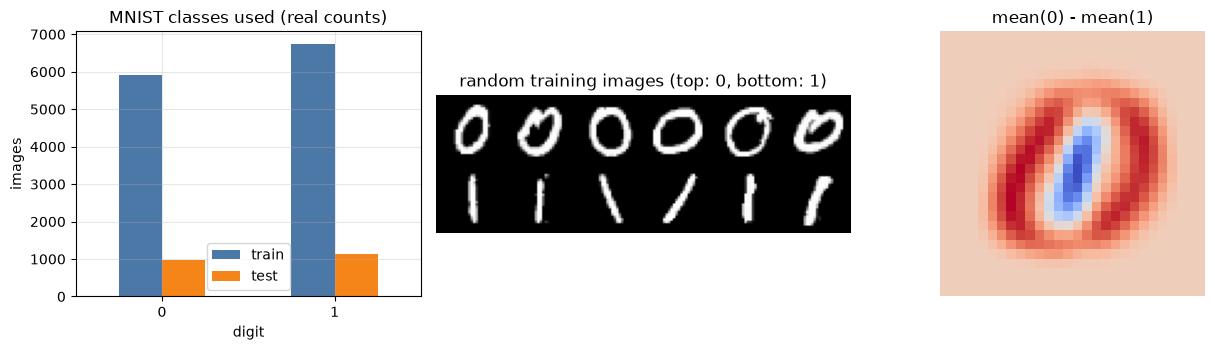

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1.2, 1.2]})
cnt = pd.DataFrame({"train": pd.Series(dtr_all).value_counts().sort_index(), "test": pd.Series(dte_all).value_counts().sort_index()})
cnt.plot.bar(ax=ax[0], color=["#4C78A8", "#F58518"]); ax[0].set_title("MNIST classes used (real counts)"); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images"); ax[0].tick_params(axis="x", rotation=0)
rr = np.random.default_rng(SEED)
tiles = []
for dgt in (0, 1):
    idx = rr.choice(np.where(dtr_all == dgt)[0], 6, replace=False)
    tiles.append(np.concatenate([Xtr_all[i].reshape(28, 28) for i in idx], axis=1))
ax[1].imshow(np.concatenate(tiles, axis=0), cmap="gray"); ax[1].set_title("random training images (top: 0, bottom: 1)"); ax[1].axis("off"); ax[1].grid(False)
ax[2].imshow(Xtr_all[dtr_all == 0].mean(0).reshape(28, 28) - Xtr_all[dtr_all == 1].mean(0).reshape(28, 28), cmap="coolwarm"); ax[2].set_title("mean(0) - mean(1)"); ax[2].axis("off"); ax[2].grid(False)
plt.tight_layout(); plt.show()

explained variance of the first components: [0.321 0.091 0.081 0.056 0.039 0.034 0.023 0.021] | cumulative 0.665


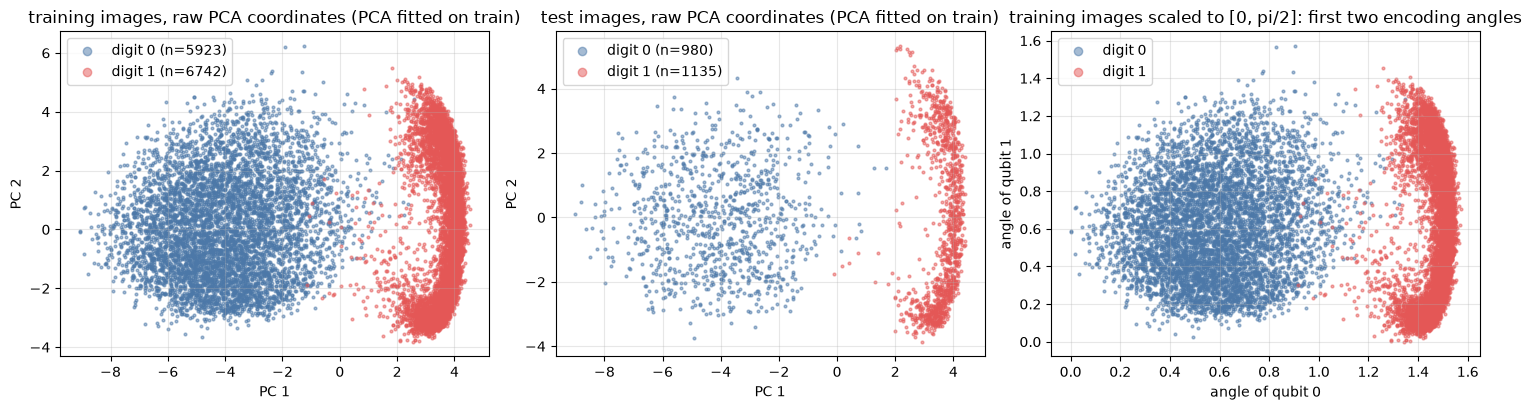

In [7]:
# PCA fitted on the TRAINING split only; the first n components serve the n-qubit models. Angles = min-max scaled training range, test clipped.
N_PCA = 8
pca = PCA(n_components=N_PCA, random_state=SEED).fit(Xtr_all)
Ptr, Pte = pca.transform(Xtr_all), pca.transform(Xte_all)
A_MAX = np.pi / 2           # CHOICE: exp(-i x sigma_y)|0> = (cos x, sin x), so x in [0, pi/2] covers the whole |0> -> |1> meridian (Eq. 3)
lo, hi = Ptr.min(0), Ptr.max(0)
ANG_TR = (Ptr - lo) / (hi - lo) * A_MAX
ANG_TE = np.clip((Pte - lo) / (hi - lo) * A_MAX, 0, A_MAX)
print("explained variance of the first components:", np.round(pca.explained_variance_ratio_, 3), "| cumulative", round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (P, dig, ttl) in zip(ax[:2], [(Ptr, dtr_all, "training"), (Pte, dte_all, "test")]):
    for dgt, col in [(0, "#4C78A8"), (1, "#E45756")]:
        m = dig == dgt
        a.scatter(P[m, 0], P[m, 1], s=4, alpha=0.5, c=col, label="digit %d (n=%d)" % (dgt, m.sum()))
    a.set_title("%s images, raw PCA coordinates (PCA fitted on train)" % ttl); a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.legend(markerscale=3)
for dgt, col in [(0, "#4C78A8"), (1, "#E45756")]:
    m = dtr_all == dgt
    ax[2].scatter(ANG_TR[m, 0], ANG_TR[m, 1], s=4, alpha=0.5, c=col, label="digit %d" % dgt)
ax[2].set_title("training images scaled to [0, pi/2]: first two encoding angles"); ax[2].set_xlabel("angle of qubit 0"); ax[2].set_ylabel("angle of qubit 1"); ax[2].legend(markerscale=3)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Every circuit below is built twice: once in **Qiskit** (drawn here) and once in our PyTorch simulator (used for all numbers). A cell asserts that both give the same final state
vector, so the drawings are of the circuits that are actually executed. The paper does not draw its circuits; the exact gate choices where it is silent are listed in the
"What had to be chosen" table and marked `# CHOICE:`.

* **A. Hardware-efficient classifier with angle encoding.** `RY(2x_q)` on every qubit (this is `exp(-i x sigma_y)|0>` of Eq. 3), then `L` layers of `RY RZ` on each qubit followed by a nearest-neighbour CNOT brick (even bonds, odd bonds alternately), then `Z` on qubit 0. Used in Fig. 2a (LOE, random angles), Theorem 3 and the trained MNIST classifiers of Fig. 2d.
* **B. Random brickwork attacked by a product adversary.** Product input state, adversary layer `u(theta, phi, lambda)` on every qubit (the product of single-qubit unitaries `W_i`), brickwork of Haar-random two-qubit unitaries, `Z` on qubit 0. Used in Fig. 2b/2c and Theorem 2.
* **C. Amplitude-encoded classifier.** the 196 pooled pixels (padded with zeros to 256 amplitudes, 8 qubits) loaded by state preparation, then the same hardware-efficient ansatz. Used for Theorem 1.

A: Qiskit circuit == simulator state, <Z0> = -0.508588


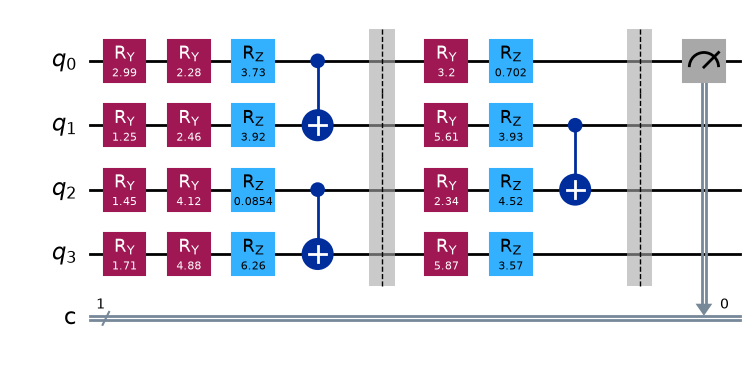

B: Qiskit circuit == simulator state == Heisenberg form <phi|Z_U|phi>, <Z0> = 0.718443


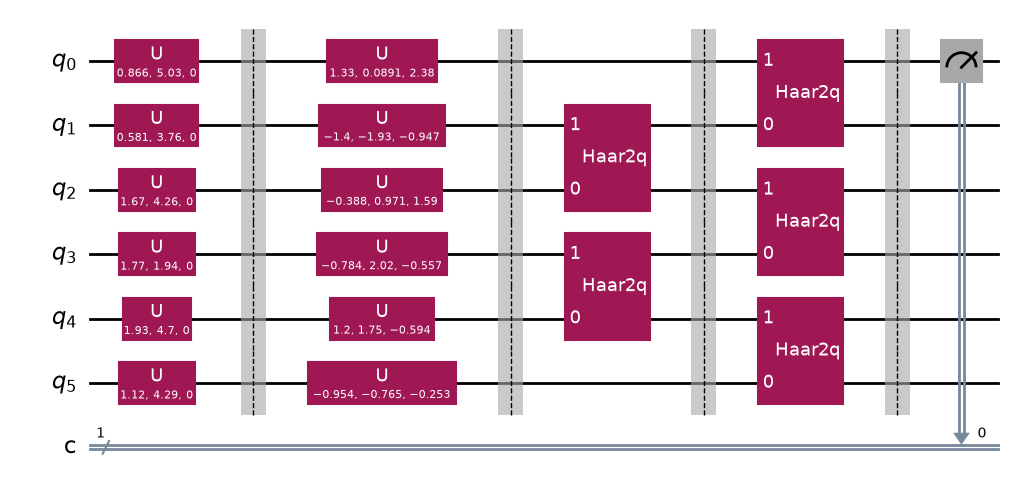

C: Qiskit circuit == simulator state, <Z0> = 0.105327


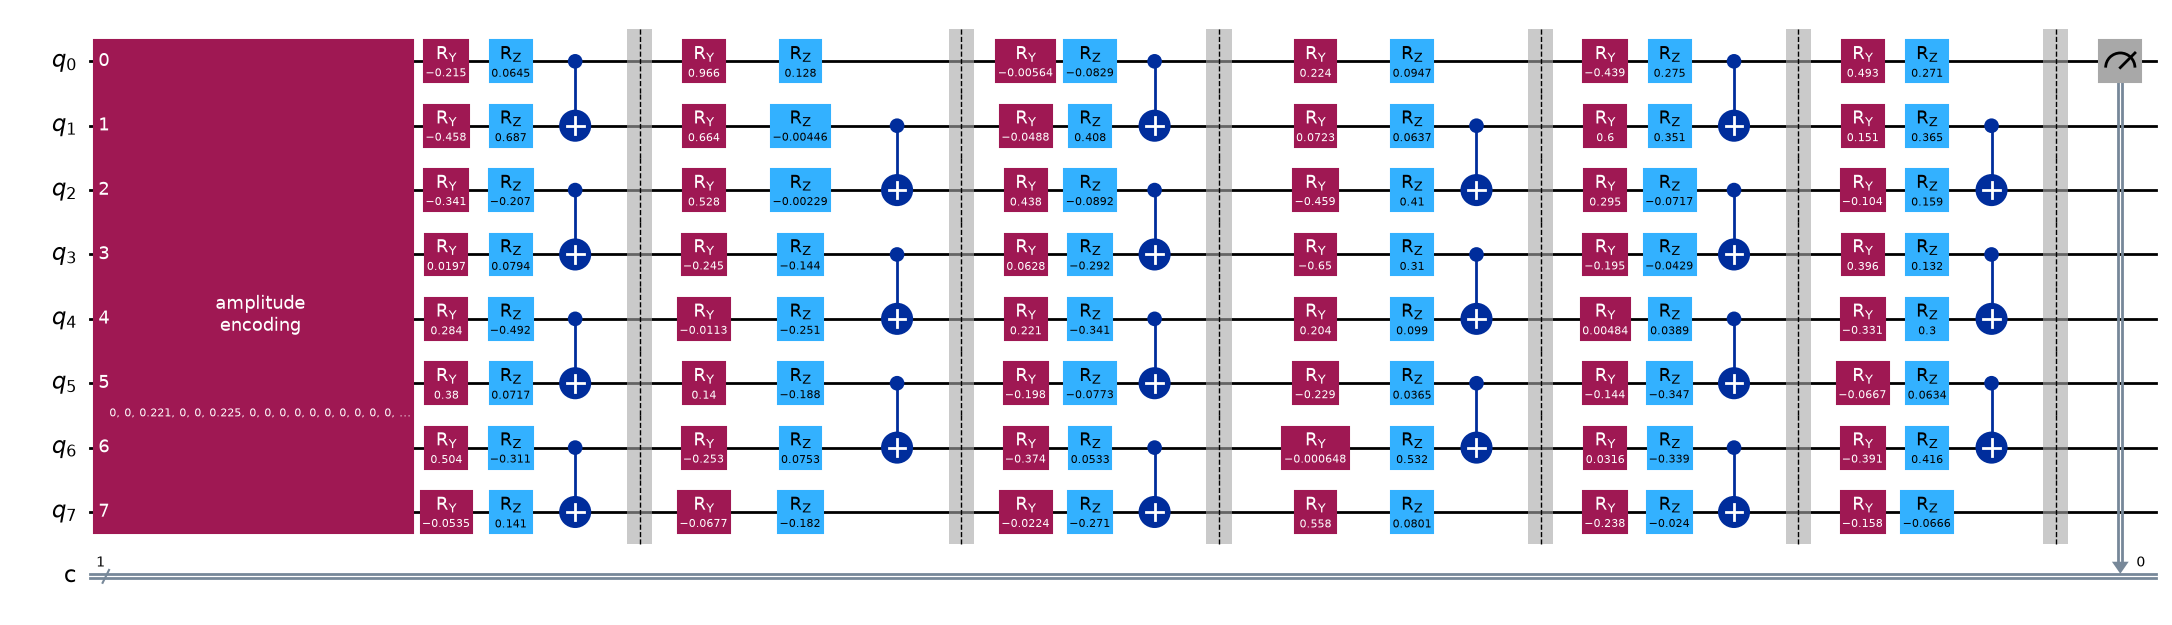


                                                              architecture  qubits  circuit depth (drawn)  trainable parameters (drawn)                                                                    where used
                     A hardware-efficient, angle encoding (shown n=4, L=2)       4                      8                            16       n in {4,6,8}, L up to 24 (Fig. 2d); n in {6,8,10}, L up to 2n (Fig. 2a)
B brickwork of Haar 2-qubit unitaries + product adversary (shown n=6, L=2)       6                      5                            18 n in {4,6,8,10}, L up to 34; trainable parameters = the adversary's 3n angles
  C amplitude encoding (196 -> 256 amplitudes) + hardware-efficient ansatz       8                     20                            96                                               exactly this circuit (n=8, L=6)

Assumptions where the paper is silent: gate set (RY RZ / Haar 2q), CNOT direction (control on the left qubit), brick parity (even bonds first 

In [8]:
from qiskit.quantum_info import Statevector

def to_qiskit_order(vec, n):
    """Our basis index has qubit 0 as most significant bit, Qiskit's as least significant: reverse the qubit axes (an involution)."""
    return np.asarray(vec).reshape([2] * n).transpose(list(range(n))[::-1]).reshape(-1)

def qc_hea(n, theta, enc=None, amp=None, measure=True):
    qc = QuantumCircuit(n, 1 if measure else 0)
    if amp is not None:
        qc.append(StatePreparation(to_qiskit_order(amp, n), label="amplitude\nencoding"), range(n))
    if enc is not None:
        for q in range(n):
            qc.ry(2 * float(enc[q]), q)
    th = np.asarray(theta)
    for l in range(th.shape[0]):
        for q in range(n):
            qc.ry(float(th[l, q, 0]), q); qc.rz(float(th[l, q, 1]), q)
        for c in range(l % 2, n - 1, 2):
            qc.cx(c, c + 1)
        qc.barrier()
    if measure:
        qc.measure(0, 0)
    return qc

def qc_brick(n, chain, L, enc_tp, adv, measure=True):
    """enc_tp: (n, 2) = (theta, phi) of the Haar-random input state u(theta, phi, 0)|0>; adv: (n, 3) adversary angles; chain[j] = layer at distance j from the output."""
    qc = QuantumCircuit(n, 1 if measure else 0)
    for q in range(n):
        qc.u(float(enc_tp[q, 0]), float(enc_tp[q, 1]), 0.0, q)
    qc.barrier()
    if adv is not None:
        for q in range(n):
            qc.u(float(adv[q, 0]), float(adv[q, 1]), float(adv[q, 2]), q)
        qc.barrier()
    for j in reversed(range(L)):
        for k, c in enumerate(range(j % 2, n - 1, 2)):
            qc.append(UnitaryGate(chain[j][k].numpy(), label="Haar2q"), [c + 1, c])      # qargs reversed: Qiskit's first qarg is the least significant bit
        qc.barrier()
    if measure:
        qc.measure(0, 0)
    return qc

def tp_state(tp):
    """(n, 2) angles -> (n, 2) single-qubit states u(theta, phi, 0)|0> = (cos(theta/2), exp(i phi) sin(theta/2))."""
    tp = torch.as_tensor(tp)
    return torch.stack([torch.cos(tp[:, 0] / 2).to(CD), torch.exp(1j * tp[:, 1].to(CD)) * torch.sin(tp[:, 0] / 2).to(CD)], -1)

def mine_state_to_qiskit_check(psi_mine, qc_nomeas, n, atol=1e-10):
    sv = Statevector(qc_nomeas).data
    return np.allclose(to_qiskit_order(psi_mine.numpy().reshape(-1), n), sv, atol=atol)

def strip(qc):
    return qc.remove_final_measurements(inplace=False)

rr = np.random.default_rng(SEED + 7)
arch_rows = []

# ---- A: hardware-efficient + angle encoding
nA, LA = 4, 2
thA = torch.as_tensor(rr.uniform(0, 2 * np.pi, (LA, nA, 2))); encA = ANG_TE[0, :nA]
qcA = qc_hea(nA, thA, enc=encA)
vA = torch.stack([torch.cos(torch.as_tensor(encA)), torch.sin(torch.as_tensor(encA))], -1).to(CD)[None]
psiA = hea_apply(prod_state(vA), thA, nA)
assert mine_state_to_qiskit_check(psiA, strip(qcA), nA), "A: simulator and Qiskit circuit disagree"
zq = Statevector(strip(qcA)).expectation_value(SparsePauliOp("I" * (nA - 1) + "Z")).real
assert abs(zq - exp_z0(psiA).item()) < 1e-10
print("A: Qiskit circuit == simulator state, <Z0> =", round(float(zq), 6))
display(qcA.draw("mpl", fold=60)); plt.close("all")
arch_rows.append(("A hardware-efficient, angle encoding (shown n=4, L=2)", nA, qcA.depth(), 2 * nA * LA, "n in {4,6,8}, L up to 24 (Fig. 2d); n in {6,8,10}, L up to 2n (Fig. 2a)"))

# ---- B: random brickwork attacked by a product adversary
nB, LB = 6, 2
chainB = [random_layer(nB, j % 2, rr) for j in range(LB)]
tp = np.stack([np.arccos(rr.uniform(-1, 1, nB)), rr.uniform(0, 2 * np.pi, nB)], 1)
advB = rr.normal(0, 1.0, (nB, 3))
qcB = qc_brick(nB, chainB, LB, tp, advB)
v = tp_state(tp)
adv_mats = U3(torch.as_tensor(advB[:, 0]), torch.as_tensor(advB[:, 1]), torch.as_tensor(advB[:, 2]))
v_adv = torch.einsum("nij,nj->ni", adv_mats, v)
psiB = brick_apply(prod_state(v_adv[None]), chainB, nB)
assert mine_state_to_qiskit_check(psiB, strip(qcB), nB), "B: simulator and Qiskit circuit disagree"
zq = Statevector(strip(qcB)).expectation_value(SparsePauliOp("I" * (nB - 1) + "Z")).real
ZU_B = heisenberg_z(dense_unitary(lambda s: brick_apply(s, chainB, nB), nB), nB)
phi = prod_state(v_adv[None])
assert abs(zq - exp_z0(psiB).item()) < 1e-10 and abs(zq - torch.einsum("bi,ij,bj->b", phi.conj(), ZU_B, phi).real.item()) < 1e-10
print("B: Qiskit circuit == simulator state == Heisenberg form <phi|Z_U|phi>, <Z0> =", round(float(zq), 6))
display(qcB.draw("mpl", fold=60)); plt.close("all")
arch_rows.append(("B brickwork of Haar 2-qubit unitaries + product adversary (shown n=6, L=2)", nB, qcB.depth(), 3 * nB, "n in {4,6,8,10}, L up to 34; trainable parameters = the adversary's 3n angles"))

# ---- C: amplitude encoding with the 8-qubit hardware-efficient ansatz (the exact model used for Theorem 1)
nC, LC = AMP_QUBITS, AMP_LAYERS
thC = torch.as_tensor(rr.normal(0, 0.3, (LC, nC, 2)))
xC = np.zeros(2 ** nC); xC[:N_AMP] = Xte_p[0]; xC = xC / np.linalg.norm(xC)
qcC = qc_hea(nC, thC, amp=xC)
psiC = hea_apply(torch.as_tensor(xC, dtype=CD)[None], thC, nC)
assert mine_state_to_qiskit_check(psiC, strip(qcC), nC), "C: simulator and Qiskit circuit disagree"
zq = Statevector(strip(qcC)).expectation_value(SparsePauliOp("I" * (nC - 1) + "Z")).real
assert abs(zq - exp_z0(psiC).item()) < 1e-10
print("C: Qiskit circuit == simulator state, <Z0> =", round(float(zq), 6))
display(qcC.draw("mpl", fold=80)); plt.close("all")
arch_rows.append(("C amplitude encoding (196 -> 256 amplitudes) + hardware-efficient ansatz", nC, qcC.depth(), 2 * nC * LC, "exactly this circuit (n=%d, L=%d)" % (nC, LC)))

print()
print(pd.DataFrame(arch_rows, columns=["architecture", "qubits", "circuit depth (drawn)", "trainable parameters (drawn)", "where used"]).to_string(index=False))
print("\nAssumptions where the paper is silent: gate set (RY RZ / Haar 2q), CNOT direction (control on the left qubit), brick parity (even bonds first at the input side for A; the layer at the measured end uses even bonds for B), no final rotation layer, measurement of Z on qubit 0 (k = 1).")

## 2. Weak attacks: Theorem 1 and the encoding scaling (Eq. 8-10)

**Theorem 1.** For `y_theta(x) = <Z>` after a unitary (or any CPTP) map, `abs(y_theta(x) - y_theta(x')) <= |psi(x) - psi(x')|_1`.
So if the encoded states are closer than `abs(y_theta(x))` in trace norm, the prediction cannot change. How useful that is depends on how far a *classical* change of the
input moves the *quantum* state:

* angle encoding of `N` values: `|psi(x)-psi(x')|_1 = 2 sqrt(N) epsilon + O(epsilon^2)` (Eq. 39),
* dense angle encoding: the same scaling in `N`,
* amplitude encoding: independent of `N` (Eq. 57).

First we measure this on **real MNIST images** (pooled to `N = 4, 16, 196, 784` pixels, every pixel moved by `+-epsilon`, `epsilon = 0.01`). For angle and dense encoding the encoded
state is a product state, so the trace distance of the pure states is `2 sqrt(1 - prod_j F_j)` exactly; for amplitude encoding we use the normalised pixel vectors. (A 784-qubit angle encoding cannot be simulated
state-vector-wise, but the product formula is exact; for `N = 6` the cell checks the formula against the simulator.)

product formulas agree with the simulator

  N  angle  dense  amplitude  pred_2sqrtN_eps
  4 0.0400 0.0289     0.1794             0.04
 16 0.0800 0.0594     0.1371             0.08
196 0.2786 0.2080     0.0820             0.28
784 0.5492 0.4108     0.0745             0.56
log-log slope of |psi-psi'|_1 versus N  ->  angle 0.497, dense 0.502, amplitude -0.174   (paper: 0.5, 0.5, 0)


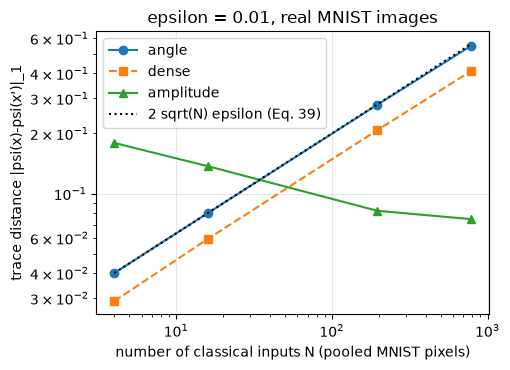

In [9]:
def tdist_angle(x, xp):
    """Trace distance of angle-encoded product states exp(-i x_j sigma_y)|0> (Eq. 3): overlap = prod cos(x_j - x'_j)."""
    F = np.prod(np.cos(x - xp) ** 2, axis=1)
    return 2 * np.sqrt(np.clip(1 - F, 0, None))

def dense_qubit_states(x):
    a, b = x[:, 0::2], x[:, 1::2]                         # (a, b) = (x_{2j-1}, x_{2j}): exp(-i b sigma_z) exp(-i a sigma_y)|0> (Eq. 4)
    return np.stack([np.exp(-1j * b) * np.cos(a), np.exp(1j * b) * np.sin(a)], -1)

def tdist_dense(x, xp):
    s, sp = dense_qubit_states(x), dense_qubit_states(xp)
    F = np.prod(np.abs((s.conj() * sp).sum(-1)) ** 2, axis=1)
    return 2 * np.sqrt(np.clip(1 - F, 0, None))

def tdist_amp(x, xp):
    c = (x * xp).sum(1) / (np.linalg.norm(x, axis=1) * np.linalg.norm(xp, axis=1))
    return 2 * np.sqrt(np.clip(1 - c ** 2, 0, None))

# check of the product formulas against the simulator (N = 6 angle encoding, N = 6 dense encoding -> 3 qubits)
r6 = np.random.default_rng(SEED)
x6, xp6 = r6.uniform(0, 1, (1, 6)), r6.uniform(0, 1, (1, 6))
v6 = lambda x: torch.stack([torch.cos(torch.as_tensor(x[0])), torch.sin(torch.as_tensor(x[0]))], -1).to(CD)[None]
p1, p2 = prod_state(v6(x6)), prod_state(v6(xp6))
td_sim = 2 * math.sqrt(1 - abs((p1.conj() * p2).sum().item()) ** 2)
assert abs(td_sim - tdist_angle(x6, xp6)[0]) < 1e-10
d1, d2 = prod_state(torch.as_tensor(dense_qubit_states(x6))), prod_state(torch.as_tensor(dense_qubit_states(xp6)))
assert abs(2 * math.sqrt(1 - abs((d1.conj() * d2).sum().item()) ** 2) - tdist_dense(x6, xp6)[0]) < 1e-10
print("product formulas agree with the simulator")

EPS_ENC = 0.01
rr = np.random.default_rng(SEED + 1)
imgs = Xte_all[:300]
rows = []
for k in (14, 7, 2, 1):
    Xp = pool_images(imgs, k); N = Xp.shape[1]
    w = rr.choice([-1.0, 1.0], size=Xp.shape)                 # every pixel moved by +-epsilon (max-norm perturbation of size epsilon)
    Xq = Xp + EPS_ENC * w
    rows.append(dict(N=N, angle=tdist_angle(Xp, Xq).mean(), dense=tdist_dense(Xp, Xq).mean(), amplitude=tdist_amp(Xp, Xq).mean(), pred_2sqrtN_eps=2 * np.sqrt(N) * EPS_ENC))
enc = pd.DataFrame(rows)
print(enc.round(4).to_string(index=False))
sl = {c: np.polyfit(np.log(enc.N), np.log(enc[c]), 1)[0] for c in ["angle", "dense", "amplitude"]}
print("log-log slope of |psi-psi'|_1 versus N  ->  angle %.3f, dense %.3f, amplitude %.3f   (paper: 0.5, 0.5, 0)" % (sl["angle"], sl["dense"], sl["amplitude"]))
RES["enc_slopes"] = sl; RES["enc_ratio_angle"] = float((enc.angle / enc.pred_2sqrtN_eps).iloc[-1])
fig, ax = plt.subplots(figsize=(5.2, 3.8))
for c, m in [("angle", "o-"), ("dense", "s--"), ("amplitude", "^-")]:
    ax.loglog(enc.N, enc[c], m, label=c)
ax.loglog(enc.N, enc.pred_2sqrtN_eps, "k:", label="2 sqrt(N) epsilon (Eq. 39)")
ax.set_xlabel("number of classical inputs N (pooled MNIST pixels)"); ax.set_ylabel("trace distance |psi(x)-psi(x')|_1"); ax.set_title("epsilon = 0.01, real MNIST images"); ax.legend()
plt.tight_layout(); plt.show()

### Theorem 1 on a real amplitude-encoded classifier (8 qubits)

Amplitude encoding is the case where the theorem has bite: a pixel change of size `epsilon` moves the state by about `2 epsilon / rms(x)`, whatever `N`. We train the 8-qubit circuit **C** (hardware-efficient, 6 layers; the images are average-pooled to 14 x 14 = 196 pixels so that the exact simulation stays cheap)
on MNIST 0 vs 1 with the paper's loss `-y y_theta` (Eq. 6), then for every test image

* compute the **certified radius** (a rigorous consequence of Theorem 1): since `|psi(x)-psi(x')|_1 = 2 sin(angle) <= 2 |x'-x|_2 / |x|_2 <= 2 epsilon sqrt(196)/|x|_2` for an `l_inf` perturbation of size `epsilon`, no attack with
  `epsilon < eps_cert = abs(y_theta(x)) |x|_2 / (2 sqrt(196))` can change the label, whatever the attacker does;
* run a strong **PGD attack** (signed gradient steps, `l_inf` ball, pixels clipped to `[0, 1]`) and bisect on `epsilon` to find the smallest successful perturbation `eps_flip` (an upper bound on the true minimum);
* check the inequality `abs(y(x') - y(x)) <= |psi(x)-psi(x')|_1` on every PGD iterate that was evaluated.

Because `eps_cert <= (true minimal epsilon) <= eps_flip`, the experiment is a proof-by-measurement that no violation occurs, and the gap between `eps_cert` and `eps_flip` shows how loose the guarantee is in practice.
As classical reference we use a logistic regression on the same pooled pixels, for which the minimal `l_inf` perturbation is exactly `abs(w.x+b) / |w|_1` (ignoring pixel clipping, which can only increase it).

In [10]:
def amp_state(X):
    Xp = torch.nn.functional.pad(X, (0, 2 ** AMP_QUBITS - X.shape[1]))
    return (Xp / Xp.norm(dim=1, keepdim=True)).to(CD)

def amp_y(X, theta):
    return exp_z0(hea_apply(amp_state(X), theta, AMP_QUBITS))

rr = np.random.default_rng(SEED + 2)
sel = rr.choice(len(Xtr_all), AMP_TRAIN_N, replace=False)
Xa = torch.as_tensor(Xtr_p[sel]); ya = torch.as_tensor(np.where(dtr_all[sel] == 0, 1.0, -1.0))
theta_amp = torch.nn.Parameter(torch.as_tensor(rr.normal(0, 0.3, (AMP_LAYERS, AMP_QUBITS, 2))))   # CHOICE: small random init
opt = torch.optim.Adam([theta_amp], lr=AMP_LR)
t0 = time.time()
for step in range(AMP_STEPS):
    idx = torch.as_tensor(rr.choice(AMP_TRAIN_N, AMP_BATCH, replace=False))
    loss = -(ya[idx] * amp_y(Xa[idx], theta_amp)).mean()                       # Eq. 6
    opt.zero_grad(); loss.backward(); opt.step()
    if step % max(1, AMP_STEPS // 6) == 0 or step == AMP_STEPS - 1:
        print("step %3d  loss %.4f" % (step, loss.item()))
theta_amp = theta_amp.detach()
yte_lab = np.where(dte_all == 0, 1.0, -1.0)
with torch.no_grad():
    y_all = torch.cat([amp_y(torch.as_tensor(Xte_p[i:i + 400]), theta_amp) for i in range(0, len(Xte_p), 400)]).numpy()
acc_amp = float((np.sign(y_all) == yte_lab).mean())
print("amplitude-encoded %d-qubit classifier: test accuracy %.4f, mean |y_theta| %.3f (%.1f s)" % (AMP_QUBITS, acc_amp, np.abs(y_all).mean(), time.time() - t0))
RES["amp_acc"] = acc_amp

# classical reference on identical inputs (the same pooled pixels): logistic regression
lr = LogisticRegression(max_iter=2000, C=1.0).fit(Xtr_p[sel], dtr_all[sel])
acc_lr = lr.score(Xte_p, dte_all)
print("logistic regression on the same %d pooled pixels: test accuracy %.4f" % (N_AMP, acc_lr))
RES["lr_acc"] = float(acc_lr)

step   0  loss 0.0471


step  33  loss -0.3011


step  66  loss -0.3151


step  99  loss -0.3095


step 132  loss -0.2817


step 165  loss -0.3361


step 198  loss -0.3096


step 199  loss -0.3133


amplitude-encoded 8-qubit classifier: test accuracy 0.9513, mean |y_theta| 0.332 (70.3 s)
logistic regression on the same 196 pooled pixels: test accuracy 0.9991


PGD + bisection on 160 test images in 32.3 s
max over all PGD iterates of |y(x')-y(x)| / |psi(x)-psi(x')|_1 = 0.7831   (Theorem 1 requires <= 1)
images where a successful attack was found below the certified radius: 0 of 160
attack found for 160 / 160 images; median eps_cert 0.0492 | median eps_flip (quantum) 0.1055 | median eps_flip (logistic regression, exact) 0.2058


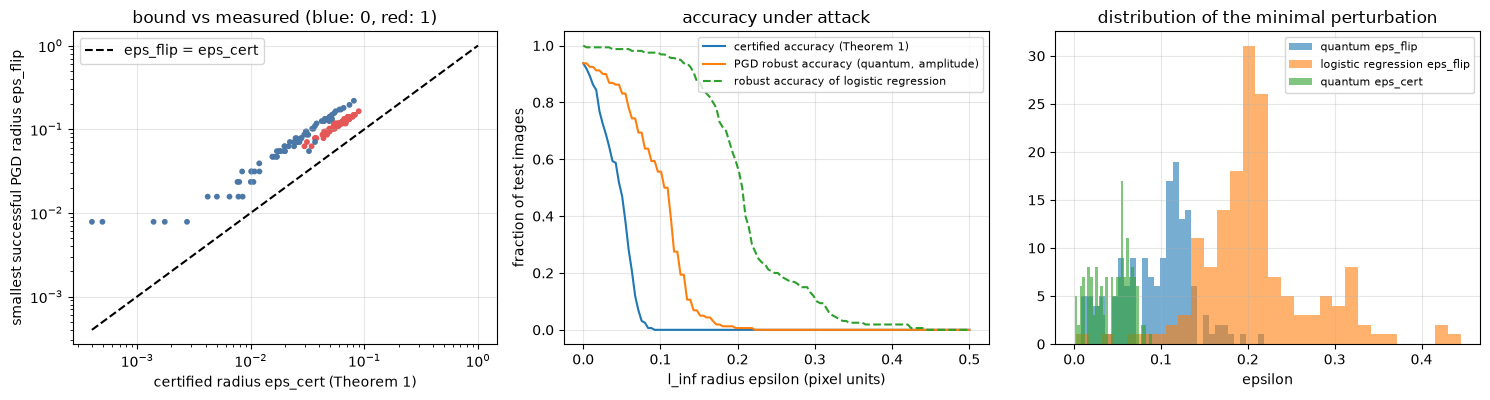

In [11]:
def pgd_flip(X, y0, eps, steps, theta):
    """PGD in the per-sample l_inf ball of radius eps (shape (B,)), pixels in [0,1]. Returns (flipped, max |dy|/trace distance over all iterates)."""
    s0 = torch.sign(y0); e = eps[:, None]; alpha = 2.5 * e / steps
    Xadv = X.clone(); flipped = torch.zeros(len(X), dtype=torch.bool); maxr = 0.0
    psi0 = amp_state(X)
    for _ in range(steps):
        Xadv.requires_grad_(True)
        g, = torch.autograd.grad((s0 * amp_y(Xadv, theta)).sum(), Xadv)
        with torch.no_grad():
            Xn = Xadv.detach() - alpha * g.sign()
            Xn = torch.min(torch.max(Xn, X - e), X + e).clamp(0, 1)
            yn = amp_y(Xn, theta)
            flipped |= torch.sign(yn) != s0
            F = (psi0.conj() * amp_state(Xn)).sum(1).abs() ** 2
            td = 2 * torch.sqrt((1 - F).clamp_min(0)); ok = td > 1e-9
            if ok.any():
                maxr = max(maxr, ((yn - y0).abs()[ok] / td[ok]).max().item())
        Xadv = Xn
    return flipped, maxr

def min_eps(X, y0, steps, iters, theta):
    B = len(X)
    hi = torch.ones(B, dtype=torch.float64); lo = torch.zeros(B, dtype=torch.float64)
    found, maxr = pgd_flip(X, y0, hi, steps, theta)
    for _ in range(iters):
        mid = (lo + hi) / 2
        fl, r = pgd_flip(X, y0, mid, steps, theta); maxr = max(maxr, r)
        hi = torch.where(fl & found, mid, hi); lo = torch.where(~fl & found, mid, lo)
    return torch.where(found, hi, torch.full_like(hi, float("inf"))), maxr

rr = np.random.default_rng(SEED + 3)
tsel = rr.choice(len(Xte_all), ATTACK_N, replace=False)
Xt = torch.as_tensor(Xte_p[tsel])
with torch.no_grad():
    y0 = amp_y(Xt, theta_amp)
correct = (torch.sign(y0).numpy() == yte_lab[tsel])
eps_cert = (y0.abs() * Xt.norm(dim=1) / (2 * math.sqrt(N_AMP))).numpy()
t0 = time.time(); eps_flip, maxr = [], 0.0
for i in range(0, ATTACK_N, 80):
    ef, r = min_eps(Xt[i:i + 80], y0[i:i + 80], PGD_STEPS, BISECT_ITERS, theta_amp); eps_flip.append(ef); maxr = max(maxr, r)
eps_flip = torch.cat(eps_flip).numpy()
dec = lr.decision_function(Xte_p[tsel]); eps_lin = np.abs(dec) / np.abs(lr.coef_).sum()
viol = int(np.sum(eps_flip < eps_cert - 1e-12))
print("PGD + bisection on %d test images in %.1f s" % (ATTACK_N, time.time() - t0))
print("max over all PGD iterates of |y(x')-y(x)| / |psi(x)-psi(x')|_1 = %.4f   (Theorem 1 requires <= 1)" % maxr)
print("images where a successful attack was found below the certified radius: %d of %d" % (viol, ATTACK_N))
fin = np.isfinite(eps_flip)
print("attack found for %d / %d images; median eps_cert %.4f | median eps_flip (quantum) %.4f | median eps_flip (logistic regression, exact) %.4f"
      % (fin.sum(), ATTACK_N, np.median(eps_cert), np.median(eps_flip[fin]), np.median(eps_lin)))
RES.update(thm1_maxratio=maxr, thm1_violations=viol, thm1_med_cert=float(np.median(eps_cert)), thm1_med_flip=float(np.median(eps_flip[fin])), thm1_med_lin=float(np.median(eps_lin)))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.1))
c = np.where(dte_all[tsel] == 0, "#4C78A8", "#E45756")
ax[0].scatter(eps_cert[fin], eps_flip[fin], s=10, c=c[fin])
lim = [min(eps_cert.min(), 1e-3), 1.0]
ax[0].plot(lim, lim, "k--", label="eps_flip = eps_cert"); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("certified radius eps_cert (Theorem 1)"); ax[0].set_ylabel("smallest successful PGD radius eps_flip"); ax[0].set_title("bound vs measured (blue: 0, red: 1)"); ax[0].legend()
grid = np.linspace(0, 0.5, 120)
ax[1].plot(grid, [(correct & (eps_cert > e)).mean() for e in grid], label="certified accuracy (Theorem 1)")
ax[1].plot(grid, [(correct & (eps_flip > e)).mean() for e in grid], label="PGD robust accuracy (quantum, amplitude)")
ax[1].plot(grid, [(((dec > 0) == (dte_all[tsel] == 1)) & (eps_lin > e)).mean() for e in grid], "--", label="robust accuracy of logistic regression")
ax[1].set_xlabel("l_inf radius epsilon (pixel units)"); ax[1].set_ylabel("fraction of test images"); ax[1].set_title("accuracy under attack"); ax[1].legend(fontsize=8)
ax[2].hist(np.minimum(eps_flip, 1.0)[fin], bins=30, alpha=0.6, label="quantum eps_flip"); ax[2].hist(eps_lin, bins=30, alpha=0.6, label="logistic regression eps_flip")
ax[2].hist(eps_cert, bins=30, alpha=0.6, label="quantum eps_cert"); ax[2].set_xlabel("epsilon"); ax[2].set_title("distribution of the minimal perturbation"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Local attacks and scrambling: Theorem 2 (OTOC bound)

If the input state is drawn from a 2-design, then for any attack unitary `W`
`Pr(abs(y(x) - y(x')) >= delta) <= <[Z_U, W]^dagger [Z_U, W]> / ((d+1) delta^2)` with `<[Z_U,W]^dagger[Z_U,W]> = 2 (1 - Re tr(Z_U W^dagger Z_U W)/d)`, an out-of-time-order correlator.
The proof is Chebyshev's inequality on the exact variance `Var(Delta y) = 2 (1 - Re tr(Z_U W^dagger Z_U W)/d)/(d+1)`. We test both the variance formula and the tail bound on Haar-random states, for a **random brickwork circuit** (circuit family B)
of growing depth `L` and the local attack `W = X` on three qubits: the measured one, a middle one and the farthest one. A shallow circuit does not carry the attack on a far qubit to the measured qubit (light cone), so there the bound is exactly zero;
once the circuit scrambles, the bound saturates at its maximum value.

Haar states per circuit: 3000, circuits: 2, delta = 1.5/sqrt(d) = 0.0938  (17 s)
variance formula: median relative deviation empirical/exact 0.013 (sampling error ~ 0.026); worst 0.040
tail bound violated (empirical > bound + 0.01) in 0 of 78 (W, L) cells
far qubit: exactly zero bound for L <= 6 (light cone of the measured qubit reaches qubit n-1 after n-1 layers)


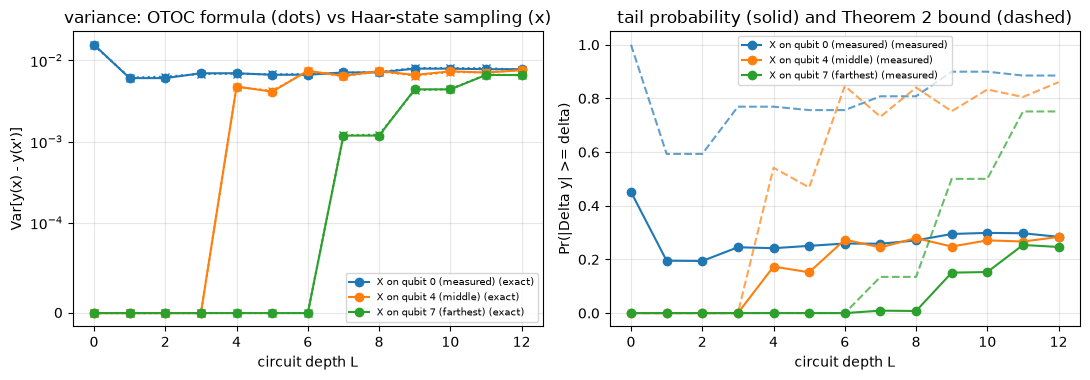

In [12]:
n = T2_QUBITS; d = 2 ** n; Lmax = max(T2_LAYERS)
cdt = torch.complex64
qlist = {"X on qubit 0 (measured)": 0, "X on qubit %d (middle)" % (n // 2): n // 2, "X on qubit %d (farthest)" % (n - 1): n - 1}
delta = 1.5 / math.sqrt(d)
rows = []
t0 = time.time()
for c_i in range(T2_CIRCUITS):
    r = np.random.default_rng(SEED + 100 + c_i)
    chain = [random_layer(n, j % 2, r) for j in range(Lmax)]
    psi = torch.as_tensor(r.standard_normal((T2_STATES, d)) + 1j * r.standard_normal((T2_STATES, d)), dtype=CD)
    psi = (psi / psi.norm(dim=1, keepdim=True))
    M = torch.diag(z0_diag(n))
    for L in range(Lmax + 1):
        if L > 0:
            M = conj_by_layer(M, chain[L - 1], n, (L - 1) % 2)
        if L not in T2_LAYERS:
            continue
        M64 = M.to(cdt); p64 = psi.to(cdt)
        y = ((p64.conj() @ M64) * p64).sum(1).real
        for name, q in qlist.items():
            flip = torch.arange(d) ^ (1 << (n - 1 - q))                       # X_q acts as an index flip
            MW = M[flip][:, flip]                                              # W^dagger Z_U W
            otoc = 1 - (M * MW.T).sum().real.item() / d                        # 1 - Re tr(Z_U W^dagger Z_U W)/d
            V = 2 * otoc / (d + 1)
            pw = p64[:, flip]                                                  # W|psi>
            yp = ((pw.conj() @ M64) * pw).sum(1).real
            dy = (y - yp)
            rows.append(dict(circuit=c_i, L=L, W=name, V_exact=V, V_emp=dy.var().item(), tail_emp=(dy.abs() >= delta).float().mean().item(), bound=min(1.0, V / delta ** 2)))
t2 = pd.DataFrame(rows)
g = t2.groupby(["W", "L"]).mean(numeric_only=True).reset_index()
rel = np.abs(g.V_emp - g.V_exact) / np.maximum(g.V_exact, 1e-12)
print("Haar states per circuit: %d, circuits: %d, delta = 1.5/sqrt(d) = %.4f  (%.0f s)" % (T2_STATES, T2_CIRCUITS, delta, time.time() - t0))
print("variance formula: median relative deviation empirical/exact %.3f (sampling error ~ %.3f); worst %.3f" % (np.median(rel[g.V_exact > 1e-9]), math.sqrt(2 / T2_STATES), rel[g.V_exact > 1e-9].max()))
print("tail bound violated (empirical > bound + 0.01) in %d of %d (W, L) cells" % ((t2.tail_emp > t2.bound + 0.01).sum(), len(t2)))
far = g[g.W.str.contains("farthest")]
print("far qubit: exactly zero bound for L <=", int(far[far.V_exact < 1e-12].L.max()), "(light cone of the measured qubit reaches qubit n-1 after n-1 layers)")
RES.update(thm2_var_reldev=float(np.median(rel[g.V_exact > 1e-9])), thm2_viol=int((t2.tail_emp > t2.bound + 0.01).sum()), thm2_cells=len(t2), thm2_zero_until=int(far[far.V_exact < 1e-12].L.max()),
           thm2_plateau=float(g[g.L == Lmax].V_exact.mean() * (d + 1) / 2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
for name in qlist:
    s = g[g.W == name]
    ax[0].plot(s.L, s.V_exact, "o-", label=name + " (exact)"); ax[0].plot(s.L, s.V_emp, "x:", color=ax[0].lines[-1].get_color())
    ax[1].plot(s.L, s.tail_emp, "o-", label=name + " (measured)"); ax[1].plot(s.L, s.bound, "--", color=ax[1].lines[-1].get_color(), alpha=0.7)
ax[0].set_xlabel("circuit depth L"); ax[0].set_ylabel("Var[y(x) - y(x')]"); ax[0].set_title("variance: OTOC formula (dots) vs Haar-state sampling (x)"); ax[0].set_yscale("symlog", linthresh=1e-4); ax[0].legend(fontsize=7)
ax[1].set_xlabel("circuit depth L"); ax[1].set_ylabel("Pr(|Delta y| >= delta)"); ax[1].set_title("tail probability (solid) and Theorem 2 bound (dashed)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. Chaos instead of scrambling: local operator entanglement (Fig. 2a)

The **local operator entanglement** (LOE) of the observable `Z_U = U^dagger Z U` is the entanglement entropy of its Choi state `(Z_U x 1)|phi+>` across a cut of the qubit chain: the dense matrix `Z_U`, written as a tensor with
indices `(out_1..out_n, in_1..in_n)`, is cut into the pairs `(out_i, in_i)` on the left versus the right, and the squared singular values (normalised) are the Schmidt probabilities `p_k`; the Renyi-2 entropy is `S2 = -log sum_k p_k^2`.
Its maximum is `n log 2` for the middle cut. The paper's Fig. 2a shows that for a hardware-efficient circuit (circuit family A) the LOE grows **linearly** with the depth, the signature of chaotic dynamics, before saturating. Because the measured qubit is the first one, the operator front needs about `n/2` layers to reach the middle cut, so the LOE stays zero for that long and then grows linearly (in steps of two layers, one CNOT brick of each parity).
As a control, a Clifford circuit (all rotation angles multiples of `pi/2`) maps `Z` to a single Pauli string, whose LOE is exactly zero at every depth.

LOE computed in 21 s


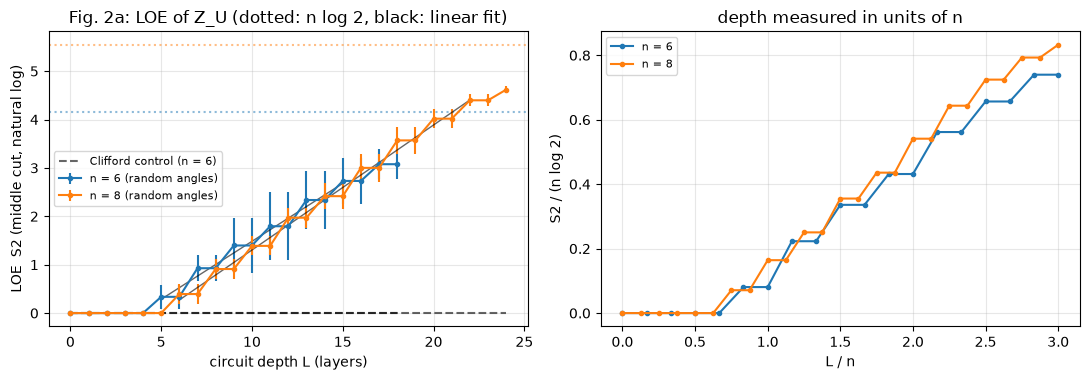

growth window (first non-zero LOE ... 90% of final value) per n: {6: (5, 15), 8: (6, 22)}
slope dS2/dL inside the window: {6: 0.239, 8: 0.258} | R^2 of the linear fit: {6: 0.974, 8: 0.99}
S2 / (n log 2) at L = 3n: {6: 0.74, 8: 0.833}
Clifford control: max S2 over all depths = 0.0


In [13]:
def loe_curve(n, Lmax, seed, clifford=False):
    r = np.random.default_rng(seed)
    ang = r.integers(0, 4, (Lmax, n, 2)) * (np.pi / 2) if clifford else r.uniform(0, 2 * np.pi, (Lmax, n, 2))
    th = torch.as_tensor(ang)
    M = torch.diag(z0_diag(n)); s2 = [choi_entropies(M, n, [n // 2])[n // 2][0]]
    for j in range(Lmax):
        M = conj_hea_layer(M, th[j], n, j % 2)
        s2.append(choi_entropies(M, n, [n // 2])[n // 2][0])
    return np.array(s2)

t0 = time.time(); loe = {}
for n_ in LOE_QUBITS:
    loe[n_] = np.stack([loe_curve(n_, 3 * n_, SEED + 200 + c) for c in range(LOE_CIRCUITS)])
cliff = {n_: np.stack([loe_curve(n_, 3 * n_, SEED + 300 + c, clifford=True) for c in range(2)]) for n_ in LOE_QUBITS[:2]}
print("LOE computed in %.0f s" % (time.time() - t0))

def growth_window(m):
    """layers between the first non-zero LOE (the operator front reaches the cut) and the first layer where 90% of the final value is reached."""
    on = int(np.argmax(m > 0.05)); off = int(np.argmax(m >= 0.9 * m[-3:].mean()))
    return on, max(off, on + 3)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
slopes, r2, windows = {}, {}, {}
for n_ in LOE_QUBITS:
    m, s = loe[n_].mean(0), loe[n_].std(0)
    ax[0].errorbar(np.arange(len(m)), m, s, marker="o", ms=3, label="n = %d (random angles)" % n_)
    ax[0].axhline(n_ * np.log(2), color=ax[0].lines[-1].get_color(), ls=":", alpha=0.5)
    on, off = growth_window(m); kk = np.arange(on, off + 1); windows[n_] = (on, off)
    slopes[n_], icpt = np.polyfit(kk, m[kk], 1); r2[n_] = float(np.corrcoef(kk, m[kk])[0, 1] ** 2)
    ax[0].plot(kk, slopes[n_] * kk + icpt, "k-", lw=1, alpha=0.6)
for n_, v in cliff.items():
    ax[0].plot(np.arange(v.shape[1]), v.mean(0), "k--", alpha=0.6, label="Clifford control (n = %d)" % n_ if n_ == LOE_QUBITS[0] else None)
ax[0].set_xlabel("circuit depth L (layers)"); ax[0].set_ylabel("LOE  S2 (middle cut, natural log)"); ax[0].set_title("Fig. 2a: LOE of Z_U (dotted: n log 2, black: linear fit)"); ax[0].legend(fontsize=8)
for n_ in LOE_QUBITS:
    ax[1].plot(np.arange(loe[n_].shape[1]) / n_, loe[n_].mean(0) / (n_ * np.log(2)), "o-", ms=3, label="n = %d" % n_)
ax[1].set_xlabel("L / n"); ax[1].set_ylabel("S2 / (n log 2)"); ax[1].set_title("depth measured in units of n"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("growth window (first non-zero LOE ... 90% of final value) per n:", windows)
print("slope dS2/dL inside the window:", {k: round(float(v), 3) for k, v in slopes.items()}, "| R^2 of the linear fit:", {k: round(v, 3) for k, v in r2.items()})
print("S2 / (n log 2) at L = 3n:", {n_: round(float(loe[n_].mean(0)[-1] / (n_ * np.log(2))), 3) for n_ in LOE_QUBITS})
print("Clifford control: max S2 over all depths =", max(float(np.abs(v).max()) for v in cliff.values()))
RES.update(loe_slopes={k: float(v) for k, v in slopes.items()}, loe_plateau={n_: float(loe[n_].mean(0)[-1] / (n_ * np.log(2))) for n_ in LOE_QUBITS},
           loe_linear_r2=r2, loe_windows=windows, loe_cliff_max=max(float(np.abs(v).max()) for v in cliff.values()))

## 5. Universal attacks: Theorem 3 (distance to the nearest product attack versus LOE)

A *perfect universal attack* flips the sign of `y_theta` on every input. Writing the flip operator `F = X x 1 x ... x 1` (it anticommutes with `Z` on the measured qubit), the attack unitary that does this is
`W_univ = U^dagger F U` (then `W_univ^dagger Z_U W_univ = -Z_U`, Eq. 16). A classical adversary using angle or dense encoding can only apply a **product** `W_1 x ... x W_n` of single-qubit unitaries. Theorem 3 bounds the distance
`D = 1 - max_{W_i} abs(tr(W_univ^dagger W_1 x ... x W_n))^2 / d^2` between `W_univ` and the closest product by the Renyi-2 LOE `S2` of `W_univ` (maximised over cuts):

`1 - exp(-S2/2) <= D <= 1 - exp(-n S2)`.

We compute `D` exactly (alternating maximisation over the `n` single-qubit unitaries with polar decompositions, many random restarts) and `S2` for hardware-efficient circuits of growing depth, and check the sandwich.
A rigorous consequence (largest singular value per cut) is that `D >= 1 - exp(-S_inf)`; we test that too. The Clifford control must give `S2 = 0` and `D = 0` (Corollary 4).

Theorem 3 sandwich evaluated on 32 (n, circuit, depth) points in 41 s
lower bound 1-exp(-S2/2) <= D holds in 32 / 32; upper bound D <= 1-exp(-n S2) holds in 32 / 32; 1-exp(-S_inf) <= D in 32 / 32
L       0    1      2      3      4      6      8      12
S2     0.0  0.0  0.272  0.416  0.718  0.916  1.577  2.398
D      0.0  0.0  0.140  0.311  0.422  0.489  0.806  0.976
lower  0.0  0.0  0.126  0.188  0.295  0.352  0.545  0.696
upper  0.0  0.0  0.765  0.916  0.964  0.971  1.000  1.000


Clifford control (L = 8): (n, S2, D) = [(4, 0.0, 0.0), (6, 0.0, 0.0)]


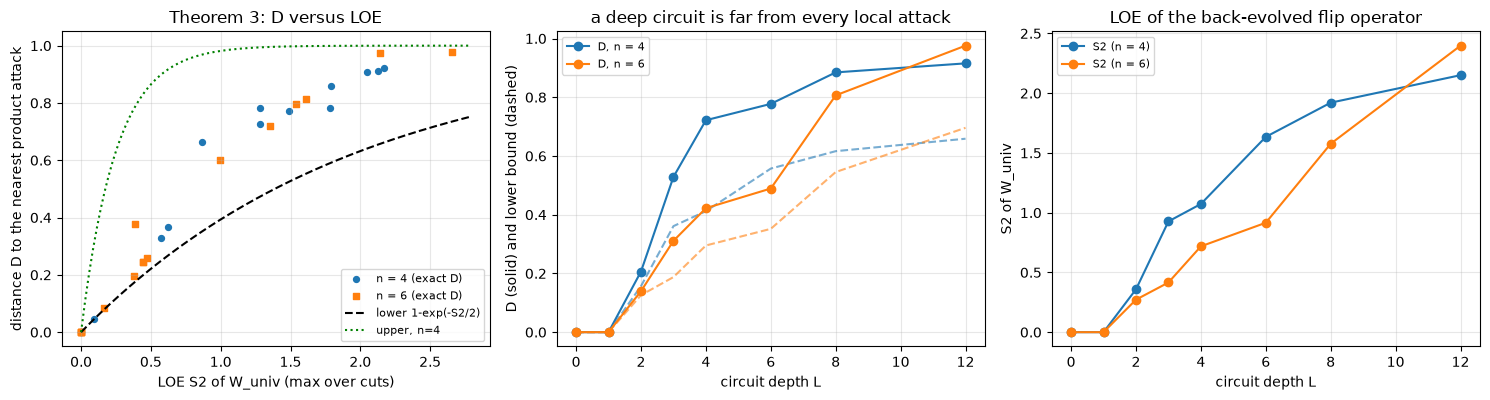

In [14]:
XM = np.array([[0, 1], [1, 0]], dtype=complex)

def flip_operator_evolved(U, n):
    """W_univ = U^dagger (X on qubit 0) U."""
    flip = torch.arange(2 ** n) ^ (1 << (n - 1))
    return U.conj().T @ U[flip, :]

def best_product_overlap(W, n, restarts, r):
    """max over single-qubit unitaries of |tr(W^dagger  W_1 x ... x W_n)|^2 / d^2  (alternating polar updates)."""
    Wc = W.reshape([2] * (2 * n)).conj().resolve_conj().numpy()
    o_idx = [chr(97 + k) for k in range(n)]; i_idx = [chr(97 + n + k) for k in range(n)]
    best = 0.0
    for _ in range(restarts):
        Ws = []
        for _k in range(n):
            q_, r_ = np.linalg.qr(r.standard_normal((2, 2)) + 1j * r.standard_normal((2, 2))); Ws.append(q_ * (np.diag(r_) / np.abs(np.diag(r_))))
        val = 0.0
        for sweep in range(40):
            for j in range(n):
                spec = "".join(o_idx + i_idx) + "".join("," + o_idx[k] + i_idx[k] for k in range(n) if k != j) + "->" + o_idx[j] + i_idx[j]
                Mj = np.einsum(spec, Wc, *[Ws[k] for k in range(n) if k != j], optimize=True)
                u, s, vh = np.linalg.svd(Mj.T)
                Ws[j] = vh.conj().T @ u.conj().T
                new = s.sum() ** 2 / 4 ** n
            if abs(new - val) < 1e-12:
                break
            val = new
        best = max(best, new)
    return best

rows = []
t0 = time.time()
for n_ in T3_QUBITS:
    for c_i in range(T3_CIRCUITS):
        r = np.random.default_rng(SEED + 400 + 10 * n_ + c_i)
        th = torch.as_tensor(r.uniform(0, 2 * np.pi, (max(T3_LAYERS), n_, 2)))
        for L in T3_LAYERS:
            U = dense_unitary(lambda s: hea_chain_apply(s, th, n_, L), n_)
            W = flip_operator_evolved(U, n_)
            ZU = heisenberg_z(U, n_)
            assert torch.allclose(W.conj().T @ ZU @ W, -ZU, atol=1e-10)                         # Eq. 16
            ent = choi_entropies(W, n_)
            S2 = max(v[0] for v in ent.values()); Sinf = max(v[1] for v in ent.values())
            D = max(0.0, 1 - best_product_overlap(W, n_, T3_RESTARTS, r))
            rows.append(dict(n=n_, circuit=c_i, L=L, S2=S2, Sinf=Sinf, D=D, lower=1 - np.exp(-S2 / 2), upper=1 - np.exp(-n_ * S2), lower_inf=1 - np.exp(-Sinf)))
t3 = pd.DataFrame(rows)
tol = 1e-6
t3["ok_lower"] = t3.D >= t3.lower - tol; t3["ok_upper"] = t3.D <= t3.upper + tol; t3["ok_lower_inf"] = t3.D >= t3.lower_inf - tol
print("Theorem 3 sandwich evaluated on %d (n, circuit, depth) points in %.0f s" % (len(t3), time.time() - t0))
print("lower bound 1-exp(-S2/2) <= D holds in %d / %d; upper bound D <= 1-exp(-n S2) holds in %d / %d; 1-exp(-S_inf) <= D in %d / %d"
      % (t3.ok_lower.sum(), len(t3), t3.ok_upper.sum(), len(t3), t3.ok_lower_inf.sum(), len(t3)))
if (~t3.ok_upper).any():
    print("upper-bound violations (D above 1-exp(-n S2)): max excess %.4f" % (t3.D - t3.upper)[~t3.ok_upper].max())
print(t3.groupby(["n", "L"])[["S2", "D", "lower", "upper"]].mean().round(3).loc[T3_QUBITS[-1]].T.to_string())

# Clifford control
cl = []
for n_ in T3_QUBITS:
    r = np.random.default_rng(SEED + 500 + n_)
    th = torch.as_tensor(r.integers(0, 4, (8, n_, 2)) * (np.pi / 2))
    U = dense_unitary(lambda s: hea_chain_apply(s, th, n_), n_); W = flip_operator_evolved(U, n_)
    ent = choi_entropies(W, n_)
    cl.append((n_, max(0.0, max(v[0] for v in ent.values())), max(0.0, 1 - best_product_overlap(W, n_, T3_RESTARTS, r))))
print("Clifford control (L = 8): (n, S2, D) =", [(a, round(b, 8), round(c, 8)) for a, b, c in cl])
RES.update(thm3_n=len(t3), thm3_lower_ok=int(t3.ok_lower.sum()), thm3_upper_ok=int(t3.ok_upper.sum()), thm3_linf_ok=int(t3.ok_lower_inf.sum()), cliff_S2=max(c[1] for c in cl), cliff_D=max(c[2] for c in cl))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.1))
for n_, mk in zip(T3_QUBITS, ["o", "s"]):
    s = t3[t3.n == n_]
    ax[0].scatter(s.S2, s.D, marker=mk, s=18, label="n = %d (exact D)" % n_)
xs = np.linspace(0, t3.S2.max() * 1.05, 200)
ax[0].plot(xs, 1 - np.exp(-xs / 2), "k--", label="lower 1-exp(-S2/2)"); ax[0].plot(xs, 1 - np.exp(-T3_QUBITS[0] * xs), "g:", label="upper, n=%d" % T3_QUBITS[0])
ax[0].set_xlabel("LOE S2 of W_univ (max over cuts)"); ax[0].set_ylabel("distance D to the nearest product attack"); ax[0].set_title("Theorem 3: D versus LOE"); ax[0].legend(fontsize=8)
for n_ in T3_QUBITS:
    s = t3[t3.n == n_].groupby("L").mean(numeric_only=True)
    ax[1].plot(s.index, s.D, "o-", label="D, n = %d" % n_); ax[1].plot(s.index, s.lower, "--", color=ax[1].lines[-1].get_color(), alpha=0.6)
ax[1].set_xlabel("circuit depth L"); ax[1].set_ylabel("D (solid) and lower bound (dashed)"); ax[1].set_title("a deep circuit is far from every local attack"); ax[1].legend(fontsize=8)
for n_ in T3_QUBITS:
    s = t3[t3.n == n_].groupby("L").mean(numeric_only=True)
    ax[2].plot(s.index, s.S2, "o-", label="S2 (n = %d)" % n_)
ax[2].set_xlabel("circuit depth L"); ax[2].set_ylabel("S2 of W_univ"); ax[2].set_title("LOE of the back-evolved flip operator"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Fig. 2b: how good must an approximate universal attack be?

Take a perfect universal attack `W_univ` of a random circuit (here a brickwork of Haar-random two-qubit unitaries of depth `2n`, `n = 6`) and rotate away from it,
`W_approx = exp(-itP) W_univ exp(itP)` with `P` a random Pauli string and `t` chosen so that the normalised 2-norm distance `epsilon = |W_approx - W_univ|_2 / sqrt(d)` has a prescribed value (Eq. 20-21; for a Pauli `P`, `epsilon = sqrt(2) abs(sin t) sqrt(1 - tr(W^dagger P W P)/d)`
exactly). We measure the fraction of Haar-random states whose prediction is flipped. Two analytic predictions are overlaid: the paper's small-`epsilon` bound `1 - 2 epsilon / pi` (Eq. 22), and the Gaussian estimate `arccos(rho)/pi`: for Haar-random states `y = <Z_U>` and `y' = <W_approx^dagger Z_U W_approx>` are jointly Gaussian with correlation `rho = tr(Z_U W_approx^dagger Z_U W_approx)/d`, and two correlated Gaussians have opposite signs with probability `arccos(rho)/pi` (this is the argument of the paper's proof, kept exact instead of expanded to first order in `epsilon`). At `epsilon = sqrt(2)` the attack is orthogonal to `W_univ` and should do no better than a random perturbation (success 1/2).

Fig. 2b: 4 circuits x 3 attacks x up to 14 epsilons, 2000 Haar states each (10 s)
 eps_target  success    sd  gauss  linear  n
       0.05    0.977 0.004  0.977   0.968 12
       0.15    0.934 0.006  0.932   0.905 12
       0.25    0.890 0.008  0.886   0.841 12
       0.35    0.846 0.008  0.841   0.777 12
       0.45    0.802 0.008  0.797   0.714 12
       0.55    0.758 0.011  0.753   0.650 12
       0.65    0.716 0.010  0.710   0.586 12
       0.75    0.675 0.013  0.668   0.523 12
       0.85    0.636 0.011  0.629   0.459 12
       0.95    0.596 0.011  0.592   0.395 12
       1.05    0.560 0.010  0.559   0.332 12
       1.15    0.530 0.010  0.531   0.268 12
       1.25    0.510 0.012  0.511   0.204 12
       1.35    0.500 0.007  0.500   0.141 12


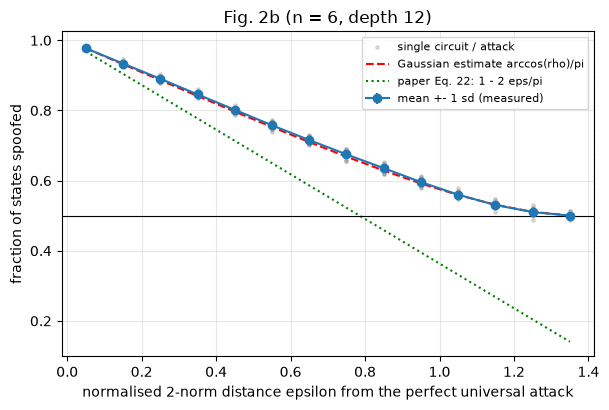

In [15]:
def pauli_string(labels):
    return torch.as_tensor(kron_all([torch.as_tensor(PAULI[l]) for l in labels]).numpy())

n = F2B_QUBITS; d = 2 ** n
EPS_TARGETS = np.linspace(0.05, 1.35, F2B_TGRID)
t0 = time.time(); rows = []
for c_i in range(F2B_CIRCUITS):
    r = np.random.default_rng(SEED + 600 + c_i)
    chain = [random_layer(n, j % 2, r) for j in range(2 * n)]
    U = dense_unitary(lambda s: brick_apply(s, chain, n), n)
    ZU = heisenberg_z(U, n); W = flip_operator_evolved(U, n)
    psi = torch.as_tensor(r.standard_normal((F2B_STATES, d)) + 1j * r.standard_normal((F2B_STATES, d)), dtype=CD); psi = psi / psi.norm(dim=1, keepdim=True)
    y = ((psi.conj() @ ZU) * psi).sum(1).real
    for a_i in range(F2B_ATTACKS):
        while True:
            lab = "".join(r.choice(list("IXYZ"), n))
            if lab != "I" * n:
                P = pauli_string(lab); a = (W.conj().T @ P @ W @ P).diagonal().sum().real.item() / d
                if a < 0.95:
                    break
        emax = math.sqrt(2 * (1 - a))
        for eps in EPS_TARGETS:
            if eps > emax:
                continue
            t = math.asin(eps / emax)
            V = math.cos(t) * torch.eye(d, dtype=CD) - 1j * math.sin(t) * P
            Wa = V @ W @ V.conj().T
            eps_num = torch.linalg.matrix_norm(Wa - W).item() / math.sqrt(d)
            ph = (Wa @ psi.T).T
            yp = ((ph.conj() @ ZU) * ph).sum(1).real
            rho = ((ZU * (Wa.conj().T @ ZU @ Wa).T).sum().real / d).item()            # correlation of y and y' for Haar states: tr(Z_U W^dagger Z_U W)/d
            rows.append(dict(circuit=c_i, attack=a_i, eps=eps_num, eps_target=eps, success=(torch.sign(yp) != torch.sign(y)).float().mean().item(),
                             gauss=math.acos(max(-1.0, min(1.0, rho))) / math.pi, linear=1 - 2 * eps_num / math.pi))
t2b = pd.DataFrame(rows)
assert np.allclose(t2b.eps, t2b.eps_target, atol=1e-8), "epsilon from the closed form disagrees with the numerical Frobenius distance"
agg = t2b.groupby("eps_target").agg(success=("success", "mean"), sd=("success", "std"), gauss=("gauss", "mean"), linear=("linear", "mean"), n=("success", "size")).reset_index()
print("Fig. 2b: %d circuits x %d attacks x up to %d epsilons, %d Haar states each (%.0f s)" % (F2B_CIRCUITS, F2B_ATTACKS, len(EPS_TARGETS), F2B_STATES, time.time() - t0))
print(agg.round(3).to_string(index=False))
RES.update(f2b_small=float(agg.success.iloc[0]), f2b_large=float(agg.success.iloc[-1]), f2b_large_eps=float(agg.eps_target.iloc[-1]),
           f2b_gauss_maxdev=float((agg.success - agg.gauss).abs().max()), f2b_lin_viol=int((agg.success < agg.linear - 0.02).sum()),
           f2b_monotone=bool((np.diff(agg.success.values) < 0.02).all()))
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.scatter(t2b.eps, t2b.success, s=6, alpha=0.25, color="gray", label="single circuit / attack")
ax.errorbar(agg.eps_target, agg.success, agg.sd, marker="o", color="C0", label="mean +- 1 sd (measured)")
ax.plot(agg.eps_target, agg.gauss, "r--", label="Gaussian estimate arccos(rho)/pi"); ax.plot(agg.eps_target, agg.linear, "g:", label="paper Eq. 22: 1 - 2 eps/pi")
ax.axhline(0.5, color="k", lw=0.8); ax.axvline(np.sqrt(2), color="k", lw=0.8, ls="--")
ax.set_xlabel("normalised 2-norm distance epsilon from the perfect universal attack"); ax.set_ylabel("fraction of states spoofed"); ax.set_title("Fig. 2b (n = %d, depth %d)" % (n, 2 * n)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Corollary 4: Clifford circuits are always attackable by a local universal attack

If `U_theta` is a Clifford circuit, the back-evolved flip operator `W_univ = U^dagger F U` is again a single Pauli string, i.e. a **product** of single-qubit Paulis, which a classical adversary with a dense angle encoding can realise exactly.
We build random Clifford circuits (the hardware-efficient family with all rotation angles multiples of `pi/2`), extract `W_univ` as a product of single-qubit operators, and apply it to Haar-random product inputs: it must flip every prediction.
For the plain angle encoding of Eq. 3 the adversary can only add `Y`-rotations, i.e. use strings in `{I, Y}^n`; such a string is a universal attack iff it anticommutes with the measured Pauli string `Q = U^dagger Z U`. We count how often one exists
(the paper argues "with high probability"; for a uniformly random Pauli string `Q` the exact probability is `1 - 2^(-n)`).

In [16]:
def peel_product_operator(M, n, tol=1e-8):
    """If M = scalar x (O_0 x ... x O_{n-1}) return the unit-norm 2x2 factors, else None."""
    T = M.reshape([2] * (2 * n)); mats = []
    for q in range(n):
        m = n - q
        perm = [0, m] + list(range(1, m)) + list(range(m + 1, 2 * m))
        U_, S_, Vh_ = torch.linalg.svd(T.permute(perm).reshape(4, -1), full_matrices=False)
        if S_.numel() > 1 and S_[1] > tol * S_[0]:
            return None
        mats.append(U_[:, 0].reshape(2, 2))
        T = (S_[0] * Vh_[0]).reshape([2] * (2 * (m - 1)))
    return mats

def pauli_name(O):
    ov = {k: abs(np.trace(PAULI[k].conj().T @ O.numpy())) / math.sqrt(2) for k in "IXYZ"}
    k = max(ov, key=ov.get)
    return k if ov[k] > 0.999 else None

n = CLIFF_QUBITS; d = 2 ** n
succ_min, n_realisable, n_total, n_pauli_ok = 1.0, 0, 0, 0
t0 = time.time()
rr = np.random.default_rng(SEED + 700)
Xin = None
for c_i in range(CLIFF_CIRCUITS):
    th = torch.as_tensor(rr.integers(0, 4, (3 * n, n, 2)) * (np.pi / 2))
    U = dense_unitary(lambda s: hea_chain_apply(s, th, n), n)
    ZU = heisenberg_z(U, n); W = flip_operator_evolved(U, n)
    fw, fq = peel_product_operator(W, n), peel_product_operator(ZU, n)
    if fw is None or fq is None:
        continue
    nw, nq = [pauli_name(o) for o in fw], [pauli_name(o) for o in fq]
    if None in nw or None in nq:
        continue
    n_pauli_ok += 1
    if c_i < 20:                                                # apply the product attack to random Haar product inputs
        v = torch.as_tensor(rr.standard_normal((500, n, 2)) + 1j * rr.standard_normal((500, n, 2))); v = v / v.norm(dim=2, keepdim=True)
        Wl = torch.stack([torch.as_tensor(PAULI[k]) for k in nw])               # (n, 2, 2): the local factors of the attack
        va = torch.einsum("nij,bnj->bni", Wl, v)
        p0, p1 = prod_state(v), prod_state(va)
        y0, y1 = ((p0.conj() @ ZU) * p0).sum(1).real, ((p1.conj() @ ZU) * p1).sum(1).real
        succ_min = min(succ_min, (torch.sign(y1) != torch.sign(y0)).float().mean().item())
    # is there a string in {I,Y}^n that anticommutes with Q?
    n_total += 1
    if any(q_ in "XZ" for q_ in nq):
        n_realisable += 1
print("random Clifford circuits tested: %d (all gave a Pauli string for Z_U and for W_univ: %d), %.0f s" % (CLIFF_CIRCUITS, n_pauli_ok, time.time() - t0))
print("local product attack W_univ on random product inputs: worst success fraction over the first 20 circuits = %.4f (Corollary 4 requires 1)" % succ_min)
print("fraction of circuits for which a {I,Y}^n string (plain angle encoding) is a universal attack: %.3f (exact expectation 1 - 2^-n = %.3f)" % (n_realisable / n_total, 1 - 2.0 ** -n))
RES.update(cliff_succ=succ_min, cliff_realisable=n_realisable / n_total, cliff_expected=1 - 2.0 ** -n, cliff_tested=n_pauli_ok)

random Clifford circuits tested: 100 (all gave a Pauli string for Z_U and for W_univ: 100), 17 s
local product attack W_univ on random product inputs: worst success fraction over the first 20 circuits = 1.0000 (Corollary 4 requires 1)
fraction of circuits for which a {I,Y}^n string (plain angle encoding) is a universal attack: 0.980 (exact expectation 1 - 2^-n = 0.984)


## 8. Fig. 2c: a learned local adversary against random circuits of growing depth

The adversary is a product of general single-qubit unitaries `U(theta, phi, lambda)` on the `n` input qubits (`3n` trainable angles), exactly the paper's modelling of an unconstrained local attacker.
It is trained with Adam on freshly drawn Haar-random product input states (`F2C_TRAIN_N` of them, batch 32, a single epoch) to *flip* the sign of the model output with a logistic loss, and evaluated on `F2C_TEST_N` held-out product states.
For every `(n, L)` there are `F2C_CIRCUITS` random brickwork circuits (grown layer by layer, so one chain of layers provides all depths). With the observable in the Heisenberg picture, `y(x') = <phi| Z_U |phi>` for the product state `phi = (x W_i)|x_i>`, so one gradient step is a single matrix product.
The random-perturbation reference is a product of Haar-random single-qubit unitaries, which flips about half of the predictions.

In [17]:
def haar_inputs(B, n, g):
    v = torch.as_tensor(g.standard_normal((B, n, 2)) + 1j * g.standard_normal((B, n, 2)), dtype=torch.complex64)
    return v / v.norm(dim=2, keepdim=True)

def qform(ZU, v, P=None, mode="u3"):
    """y' = <phi|Z_U|phi> with phi = prod_i (W_i v_i);  P: (n, 3) U3 angles ('u3') or (n,) RY shifts of the encoded angle ('ry')."""
    if P is not None:
        if mode == "ry":
            P = torch.stack([2 * P, torch.zeros_like(P), torch.zeros_like(P)], 1)
        W = U3(P[:, 0], P[:, 1], P[:, 2]).to(torch.complex64)
        v = torch.einsum("nij,bnj->bni", W, v)
    phi = prod_state(v)
    return (phi.conj() * (phi @ ZU.T)).sum(1).real

def train_adversary(ZU, sampler, n, steps, batch, lr, seed, mode="u3"):
    g = torch.Generator().manual_seed(seed)
    P = (0.1 * torch.randn(n, 3, generator=g, dtype=torch.float64) if mode == "u3" else 0.1 * torch.randn(n, generator=g, dtype=torch.float64)).requires_grad_()
    opt = torch.optim.Adam([P], lr=lr)
    with torch.no_grad():
        y0 = qform(ZU, sampler(256))
        scale = 1.0 / max(float(y0.pow(2).mean().sqrt()), 1e-3)             # CHOICE: logit = y' / rms(y): makes the logistic loss scale-free
    for _ in range(steps):
        v = sampler(batch)
        with torch.no_grad():
            tgt = -torch.sign(qform(ZU, v))
        loss = torch.nn.functional.softplus(-tgt * scale * qform(ZU, v, P, mode)).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return P.detach()

@torch.no_grad()
def success_rate(ZU, v_test, P=None, mode="u3", chunk=2000, labels=None):
    flips, right = 0, 0
    for i in range(0, len(v_test), chunk):
        vv = v_test[i:i + chunk]
        y0, y1 = qform(ZU, vv), qform(ZU, vv, P, mode)
        flips += (torch.sign(y0) != torch.sign(y1)).sum().item()
        if labels is not None:
            right += (torch.sign(y1) == torch.as_tensor(labels[i:i + chunk])).sum().item()
    return flips / len(v_test), right / len(v_test)

def random_u3(n, g):
    return torch.stack([torch.acos(torch.as_tensor(g.uniform(-1, 1, n))), torch.as_tensor(g.uniform(0, 2 * np.pi, n)), torch.as_tensor(g.uniform(0, 2 * np.pi, n))], 1)

n = 4 done (80 s)


n = 6 done (171 s)


n = 8 done (368 s)


n       4      6      8
L                      
0   0.976  0.978  0.987
1   0.902  0.908  0.922
2   0.825  0.840  0.876
4   0.693  0.725  0.681
6   0.646  0.664  0.638
8   0.614  0.606  0.629
12  0.632  0.567  0.557
16  0.612  0.530  0.566
24  0.612  0.520  0.511
random-perturbation baseline (mean over all cells): 0.506


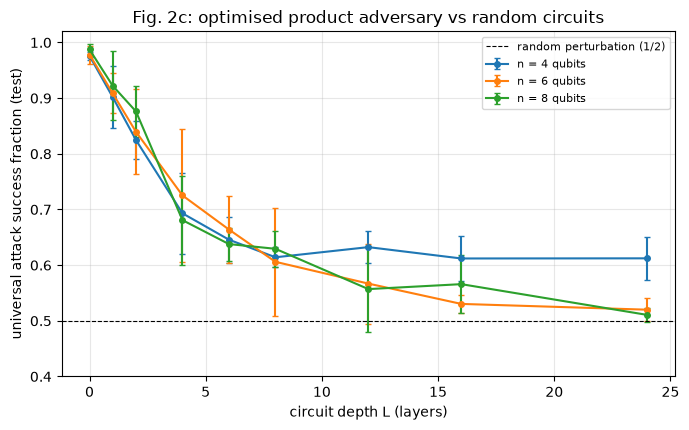

{4: {'L0': 0.976, 'Lmax': 0.612, 'sd': 0.038, 'spearman': -0.967}, 6: {'L0': 0.978, 'Lmax': 0.52, 'sd': 0.02, 'spearman': -1.0}, 8: {'L0': 0.987, 'Lmax': 0.511, 'sd': 0.012, 'spearman': -0.983}}


In [18]:
steps = F2C_TRAIN_N // F2C_BATCH
rows, base_rows = [], []
t0 = time.time()
for n_ in F2C_QUBITS:
    gt = np.random.default_rng(SEED + 800 + n_)
    v_test = haar_inputs(F2C_TEST_N, n_, gt)
    for c_i in range(F2C_CIRCUITS):
        r = np.random.default_rng(SEED + 1000 * n_ + c_i)
        M = torch.diag(z0_diag(n_))
        for L in range(max(F2C_LAYERS) + 1):
            if L > 0:
                M = conj_by_layer(M, random_layer(n_, (L - 1) % 2, r), n_, (L - 1) % 2)
            if L not in F2C_LAYERS:
                continue
            ZU = M.to(torch.complex64)
            gtr = np.random.default_rng(SEED + 10 * L + c_i + 100000 * n_)
            P = train_adversary(ZU, lambda B: haar_inputs(B, n_, gtr), n_, steps, F2C_BATCH, F2C_LR, SEED + L + c_i, "u3")
            s, _ = success_rate(ZU, v_test, P)
            rb = np.mean([success_rate(ZU, v_test[:1000], random_u3(n_, gt))[0] for _ in range(6)])
            rows.append(dict(n=n_, L=L, circuit=c_i, success=s, random=rb))
    print("n = %d done (%.0f s)" % (n_, time.time() - t0), flush=True)
t2c = pd.DataFrame(rows)
agg = t2c.groupby(["n", "L"]).agg(success=("success", "mean"), sd=("success", "std"), random=("random", "mean")).reset_index()
print(agg.pivot(index="L", columns="n", values="success").round(3).to_string())
print("random-perturbation baseline (mean over all cells):", round(float(t2c.random.mean()), 3))
fig, ax = plt.subplots(figsize=(7, 4.4))
for n_ in F2C_QUBITS:
    s = agg[agg.n == n_]
    ax.errorbar(s.L, s.success, s.sd.fillna(0), marker="o", ms=4, capsize=2, label="n = %d qubits" % n_)
ax.axhline(0.5, color="k", ls="--", lw=0.8, label="random perturbation (1/2)")
ax.set_xlabel("circuit depth L (layers)"); ax.set_ylabel("universal attack success fraction (test)"); ax.set_ylim(0.4, 1.02); ax.set_title("Fig. 2c: optimised product adversary vs random circuits"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
Lmax_ = max(F2C_LAYERS)
RES["f2c"] = {int(n_): dict(L0=float(agg[(agg.n == n_) & (agg.L == 0)].success.iloc[0]), Lmax=float(agg[(agg.n == n_) & (agg.L == Lmax_)].success.iloc[0]), sd=float(agg[(agg.n == n_) & (agg.L == Lmax_)].sd.iloc[0]),
                            spearman=float(pd.Series(agg[agg.n == n_].L.values).corr(pd.Series(agg[agg.n == n_].success.values), method="spearman"))) for n_ in F2C_QUBITS}
RES["f2c_random"] = float(t2c.random.mean())
print({k: {a: round(b, 3) for a, b in v.items()} for k, v in RES["f2c"].items()})

## 9. Fig. 2d: a trained MNIST classifier against a learned local adversary

For each `(n, L)` we train the hardware-efficient classifier (circuit **A**: angle encoding of the `n` PCA features, `L` layers) on MNIST 0 vs 1 with the paper's loss `-y y_theta` (Eq. 6), starting from **random angles** uniform in `[0, 2 pi)` (`# CHOICE:` a generic circuit is chaotic, the regime of the paper's guarantees; Adam, learning rate 0.05, `F2D_STEPS` steps). Then we train the same kind of adversary as above, now on real
encoded images: one epoch over the training images, batch 32, and measure on the held-out MNIST test images the fraction of predictions that flip. Two adversaries are compared: the **paper's** general product of single-qubit unitaries (an over-estimate of what a classical attacker can do,
as the paper notes), and a **realisable** one that can only shift the encoded angles (`x_i -> x_i + w_i`, an additive perturbation of the PCA features, unbounded in size, i.e. a pure `RY` rotation of each qubit). We also compute the LOE of the trained observable `Z_U`, the quantity the theory ties to robustness, and run an ablation with *gentle* training (learning rate 0.005, so that the circuit stays close to its random, chaotic initialisation) for the largest `n` at large depth. The classical baselines (RandomForest and RBF-SVC) are trained on exactly the same `n` angles.
The PCA / scaling were fitted on the training split only (see the dataset section).

In [19]:
def enc_states(A):
    A = torch.as_tensor(A)
    return torch.stack([torch.cos(A), torch.sin(A)], -1).to(torch.complex64)

def train_classifier(n, L, Atr, ytr, seed, steps, batch=100, lr=0.05):
    g = np.random.default_rng(seed)
    th = torch.nn.Parameter(torch.as_tensor(g.uniform(0, 2 * np.pi, (L, n, 2))))
    opt = torch.optim.Adam([th], lr=lr)
    v_all = enc_states(Atr).to(torch.complex128); y_all = torch.as_tensor(ytr)
    for _ in range(steps):
        idx = torch.as_tensor(g.choice(len(y_all), batch, replace=False))
        out = exp_z0(hea_apply(prod_state(v_all[idx]), th, n))
        loss = -(y_all[idx] * out).mean()                                   # Eq. 6
        opt.zero_grad(); loss.backward(); opt.step()
    return th.detach()

standard n=4 L= 1 acc 0.989 LOE -0.00 | adversary success: general 0.997, RY-only 0.997, random 0.305  (10 s)


standard n=4 L= 2 acc 0.991 LOE -0.00 | adversary success: general 0.998, RY-only 0.999, random 0.416  (17 s)


standard n=4 L= 4 acc 0.986 LOE 0.09 | adversary success: general 0.994, RY-only 0.992, random 0.424  (28 s)


standard n=4 L= 8 acc 0.993 LOE 0.45 | adversary success: general 0.997, RY-only 0.994, random 0.505  (55 s)


standard n=4 L=12 acc 0.992 LOE 1.19 | adversary success: general 0.994, RY-only 0.986, random 0.555  (84 s)


...

standard n=6 L=12 acc 0.992 LOE 0.33 | adversary success: general 0.999, RY-only 0.998, random 0.757  (253 s)


standard n=6 L=16 acc 0.988 LOE 0.34 | adversary success: general 0.993, RY-only 0.993, random 0.645  (330 s)


gentle   n=6 L= 8 acc 0.993 LOE 0.71 | adversary success: general 0.997, RY-only 0.996, random 0.550  (378 s)


gentle   n=6 L=12 acc 0.990 LOE 0.82 | adversary success: general 0.995, RY-only 0.993, random 0.761  (459 s)


gentle   n=6 L=16 acc 0.989 LOE 1.95 | adversary success: general 0.994, RY-only 0.995, random 0.599  (576 s)


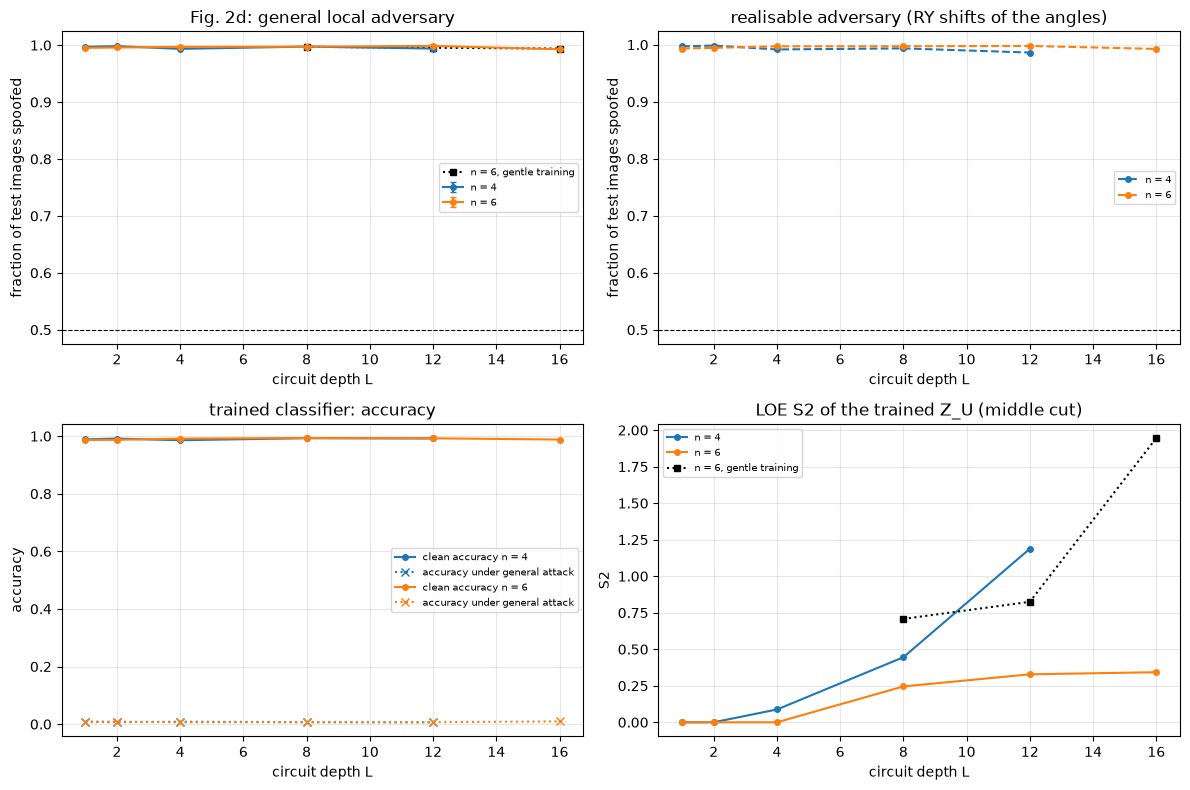


clean test accuracy on the same angle inputs (MNIST 0 vs 1):
 qubits  RandomForest  SVC_rbf  quantum_mean  quantum_best  quantum_L1
      4        0.9953   0.9976        0.9902        0.9929      0.9887
      6        0.9957   0.9976        0.9899        0.9934      0.9868
trained model (n=4, L=2) executed in Qiskit gives the same state as the simulator

n = 6: LOE S2 (middle cut; maximum n log 2 = 4.16) of the trained observable Z_U vs a random-angle circuit of the same depth
 L  trained classifier  random angles
 1               -0.00           0.00
 2               -0.00           0.00
 4                0.00           0.00
 8                0.25           0.93
12                0.33           1.79
16                0.34           2.73


In [20]:
rr = np.random.default_rng(SEED + 4)
sub = rr.choice(len(ANG_TR), F2D_TRAIN_N, replace=False)
lab_tr = np.where(dtr_all == 0, 1.0, -1.0); lab_te = np.where(dte_all == 0, 1.0, -1.0)
adv_order = rr.permutation(len(ANG_TR))[:F2D_ADV_N]
steps_adv = F2D_ADV_N // F2C_BATCH
rows, t0 = [], time.time()
trained_demo = None
plan = [("standard", 0.05, n_, [l for l in F2D_LAYERS if l <= 3 * n_]) for n_ in F2D_QUBITS] + [("gentle", 0.005, F2D_QUBITS[-1], [l for l in F2D_LAYERS if 8 <= l <= 3 * F2D_QUBITS[-1]])]
for init, lr_, n_, Ls in plan:
    Atr, Ate = ANG_TR[:, :n_], ANG_TE[:, :n_]
    v_te = enc_states(Ate)
    for L in Ls:
        th = train_classifier(n_, L, Atr[sub], lab_tr[sub], SEED + L + 10 * n_, F2D_STEPS, lr=lr_)
        with torch.no_grad():
            U = dense_unitary(lambda s: hea_apply(s, th, n_), n_)
            yq = exp_z0(hea_apply(prod_state(v_te.to(CD)), th, n_))
        ZUd = heisenberg_z(U, n_); ZU = ZUd.to(torch.complex64)
        acc = float((torch.sign(yq).numpy() == lab_te).mean())
        assert torch.allclose(qform(ZU, v_te).double(), yq, atol=1e-4), "Heisenberg form disagrees with the circuit"
        if trained_demo is None and n_ == F2D_QUBITS[0] and L >= 2 and init == "standard":
            trained_demo = (n_, L, th.clone())
        res = dict(train=init, n=n_, L=L, clean_acc=acc, loe=choi_entropies(ZUd, n_, [n_ // 2])[n_ // 2][0])
        for mode, K in [("u3", F2D_ADVERS), ("ry", max(2, F2D_ADVERS // 4))]:
            ss, aa = [], []
            for k in range(K):
                pos = [0]
                def sampler(B, pos=pos):
                    idx = adv_order[pos[0]:pos[0] + B]; pos[0] = (pos[0] + B) % max(1, len(adv_order) - B)
                    return enc_states(Atr[idx])
                P = train_adversary(ZU, sampler, n_, steps_adv, F2C_BATCH, F2C_LR, SEED + 31 * k + L + 7 * n_, mode)
                s_, a_ = success_rate(ZU, v_te, P, mode, labels=lab_te)
                ss.append(s_); aa.append(a_)
            res[mode] = float(np.mean(ss)); res[mode + "_sd"] = float(np.std(ss)); res[mode + "_acc"] = float(np.mean(aa))
        g_ = np.random.default_rng(SEED + L)
        res["random"] = float(np.mean([success_rate(ZU, v_te, random_u3(n_, g_))[0] for _ in range(10)]))
        rows.append(res)
        print("%-8s n=%d L=%2d acc %.3f LOE %.2f | adversary success: general %.3f, RY-only %.3f, random %.3f  (%.0f s)" % (init, n_, L, acc, res["loe"], res["u3"], res["ry"], res["random"], time.time() - t0), flush=True)
t2d_all = pd.DataFrame(rows)
t2d = t2d_all[t2d_all.train == "standard"].reset_index(drop=True); t2d_small = t2d_all[t2d_all.train == "gentle"]

fig, ax = plt.subplots(2, 2, figsize=(12, 8)); ax = ax.ravel()
for n_ in F2D_QUBITS:
    s = t2d[t2d.n == n_]
    ax[0].errorbar(s.L, s.u3, s.u3_sd, marker="o", ms=4, capsize=2, label="n = %d" % n_)
    ax[1].plot(s.L, s.ry, "o--", ms=4, label="n = %d" % n_)
    ax[2].plot(s.L, s.clean_acc, "o-", ms=4, label="clean accuracy n = %d" % n_)
    ax[2].plot(s.L, s.u3_acc, "x:", color=ax[2].lines[-1].get_color(), label="accuracy under general attack")
    ax[3].plot(s.L, s.loe, "o-", ms=4, label="n = %d" % n_)
if len(t2d_small):
    ax[0].plot(t2d_small.L, t2d_small.u3, "k:", marker="s", ms=4, label="n = %d, gentle training" % F2D_QUBITS[-1]); ax[3].plot(t2d_small.L, t2d_small.loe, "k:", marker="s", ms=4, label="n = %d, gentle training" % F2D_QUBITS[-1])
for a, t_ in zip(ax, ["Fig. 2d: general local adversary", "realisable adversary (RY shifts of the angles)", "trained classifier: accuracy", "LOE S2 of the trained Z_U (middle cut)"]):
    a.set_xlabel("circuit depth L"); a.set_title(t_); a.legend(fontsize=7)
ax[0].axhline(0.5, color="k", ls="--", lw=0.8); ax[1].axhline(0.5, color="k", ls="--", lw=0.8)
ax[0].set_ylabel("fraction of test images spoofed"); ax[1].set_ylabel("fraction of test images spoofed"); ax[2].set_ylabel("accuracy"); ax[3].set_ylabel("S2")
plt.tight_layout(); plt.show()

# classical baselines on exactly the same angles + the executed-circuit check for a trained model
base = []
for n_ in F2D_QUBITS:
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(ANG_TR[sub, :n_], dtr_all[sub])
    sv = SVC(kernel="rbf", C=1.0).fit(ANG_TR[sub, :n_], dtr_all[sub])
    q = t2d[t2d.n == n_].clean_acc
    base.append(dict(qubits=n_, RandomForest=rf.score(ANG_TE[:, :n_], dte_all), SVC_rbf=sv.score(ANG_TE[:, :n_], dte_all), quantum_mean=q.mean(), quantum_best=q.max(), quantum_L1=float(t2d[(t2d.n == n_) & (t2d.L == 1)].clean_acc.iloc[0])))
base = pd.DataFrame(base)
print("\nclean test accuracy on the same angle inputs (MNIST 0 vs 1):")
print(base.round(4).to_string(index=False))
if "qc_hea" in globals() and trained_demo is not None:
    n_, L, th = trained_demo
    qc_t = qc_hea(n_, th, enc=ANG_TE[0, :n_])
    v1 = torch.stack([torch.cos(torch.as_tensor(ANG_TE[0, :n_])), torch.sin(torch.as_tensor(ANG_TE[0, :n_]))], -1).to(CD)[None]
    assert mine_state_to_qiskit_check(hea_apply(prod_state(v1), th, n_), strip(qc_t), n_)
    print("trained model (n=%d, L=%d) executed in Qiskit gives the same state as the simulator" % (n_, L))
# diagnostic: LOE of the trained observables versus random-angle circuits of the same size and depth (section 4)
if 6 in loe:
    diag = [(L, float(t2d[(t2d.n == 6) & (t2d.L == L)].loe.iloc[0]), float(loe[6].mean(0)[L])) for L in sorted(set(t2d[t2d.n == 6].L)) if L < loe[6].shape[1]]
    print("\nn = 6: LOE S2 (middle cut; maximum n log 2 = %.2f) of the trained observable Z_U vs a random-angle circuit of the same depth" % (6 * np.log(2)))
    print(pd.DataFrame(diag, columns=["L", "trained classifier", "random angles"]).round(2).to_string(index=False))
RES["f2d"] = t2d; RES["f2d_small"] = t2d_small; RES["f2d_base"] = base
RES["f2d_loe_diag"] = diag if 6 in loe else []

**What this experiment shows here.** For every `(n, L)` tested the learned product adversary spoofs more than 99% of the test images, with the paper's general single-qubit unitaries and with the realisable angle shifts alike, and the success does not fall with the depth or with `n`. The paper reports the opposite trend for its trained MNIST classifier (a transition near `2n` layers and weaker attacks for larger systems).
The diagnostic above gives a candidate explanation: gradient training with the loss of Eq. 6 does not leave the circuit chaotic. The LOE of the trained observable `Z_U` stays far below that of a random-angle circuit of the same depth (section 4), and a classifier of low operator entanglement has, by Theorem 3, a nearby product attack; even with gentle training, where the LOE is kept larger, the 0-vs-1 task is so easy that the inputs occupy a thin region of the state space on which a single product unitary can flip every label.
So this notebook does **not** reproduce the depth-dependent robustness of Fig. 2d, in the system sizes accessible here (`n <= 6` in FAST mode); the random-circuit results of Fig. 2c and all analytic statements are reproduced.

## 10. Side-by-side comparison with the paper

The paper reports **no numeric table**: every result is a theorem or a plot. A claim is therefore marked *reproduced* when the measured quantity agrees with the paper's statement within the stated tolerance, *not reached* when it does not,
and *cannot be checked* when the paper gives no number or procedure to compare with (for example the exact curves of Fig. 2c/2d, which also depend on unreported qubit numbers and architectures).

In [21]:
f2c, f2d = RES["f2c"], RES["f2d"]
rows = []
def add(claim, paper, measured, ok, note=""):
    ok = None if ok is None else bool(ok)
    rows.append(dict(claim=claim, paper=paper, notebook=measured, verdict=("reproduced" if ok is True else ("not reached" if ok is False else "cannot be checked")) + (" (%s)" % note if note else "")))

# Eq. 8-10
s = RES["enc_slopes"]
add("Eq. 8-10: |psi(x)-psi(x')|_1 scales as sqrt(N) (angle, dense), not at all (amplitude)", "slope 1/2, 1/2, 0 in log-log",
    "slopes %.2f / %.2f / %.2f; angle value / (2 sqrt(N) eps) = %.2f at N=784" % (s["angle"], s["dense"], s["amplitude"], RES["enc_ratio_angle"]),
    abs(s["angle"] - 0.5) < 0.07 and abs(s["dense"] - 0.5) < 0.07 and abs(s["amplitude"]) < 0.25)
# Thm 1
add("Thm. 1: |dy| <= trace distance (weak attacks)", "holds for every input and attack",
    "max |dy| / |dpsi|_1 = %.3f over all PGD iterates; %d / %d attacks below the certified radius" % (RES["thm1_maxratio"], RES["thm1_violations"], ATTACK_N),
    RES["thm1_maxratio"] <= 1 + 1e-9 and RES["thm1_violations"] == 0)
add("Thm. 1 is useful in practice (amplitude encoding, real data)", "robust if y_theta is not small (qualitative)",
    "median certified radius %.3f vs median PGD radius %.3f vs logistic regression %.3f (pixel units); accuracy %.3f" % (RES["thm1_med_cert"], RES["thm1_med_flip"], RES["thm1_med_lin"], RES["amp_acc"]),
    None, "no number in the paper; the certificate is %.1fx below the attack" % (RES["thm1_med_flip"] / max(RES["thm1_med_cert"], 1e-9)))
# Thm 2
add("Thm. 2: variance / tail bound with the OTOC", "Pr(|dy|>=delta) <= <[Z_U,W]^2>/((d+1) delta^2)",
    "median relative deviation of Var from the formula %.3f; tail-bound violations %d / %d cells" % (RES["thm2_var_reldev"], RES["thm2_viol"], RES["thm2_cells"]),
    RES["thm2_viol"] == 0 and RES["thm2_var_reldev"] < 0.1)
add("Thm. 2: shallow circuits cannot be attacked on distant qubits", "OTOC small for non-scrambling circuits",
    "bound exactly 0 up to depth L = %d for X on the farthest qubit (n = %d)" % (RES["thm2_zero_until"], T2_QUBITS), RES["thm2_zero_until"] == T2_QUBITS - 2)
# Fig 2a
lin = min(RES["loe_linear_r2"].values()); pl = RES["loe_plateau"]
add("Fig. 2a: LOE grows linearly with depth for hardware-efficient circuits (chaos)", "linear growth, then plateau",
    "R^2 of the linear fit inside the growth window >= %.3f; slopes %s per layer; S2/(n log 2) at L=3n: %s" % (lin, {k: round(v, 2) for k, v in RES["loe_slopes"].items()}, {k: round(v, 2) for k, v in pl.items()}),
    lin > 0.95 and all(v > 0.5 for v in pl.values()))
add("Clifford circuits have zero LOE", "S2 = 0 (Cor. 4 proof)", "max S2 over all depths = %.1e" % RES["loe_cliff_max"], RES["loe_cliff_max"] < 1e-6)
# Thm 3
add("Thm. 3 lower bound 1-exp(-S2/2) <= D", "holds", "%d / %d points" % (RES["thm3_lower_ok"], RES["thm3_n"]), RES["thm3_lower_ok"] == RES["thm3_n"])
add("Thm. 3 upper bound D <= 1-exp(-n S2)", "holds", "%d / %d points" % (RES["thm3_upper_ok"], RES["thm3_n"]), RES["thm3_upper_ok"] == RES["thm3_n"],
    "" if RES["thm3_upper_ok"] == RES["thm3_n"] else "see the discussion of the upper bound below")
# Cor 4
add("Cor. 4: Clifford circuits admit a universal local attack", "D = 0, success 100%",
    "success %.4f on random product inputs; S2 = %.1e, D = %.1e; {I,Y}^n realisable for %.3f of circuits (exact expectation %.3f)" % (RES["cliff_succ"], RES["cliff_S2"], RES["cliff_D"], RES["cliff_realisable"], RES["cliff_expected"]),
    RES["cliff_succ"] > 0.9999 and RES["cliff_S2"] < 1e-6 and RES["cliff_D"] < 1e-6)
# Fig 2b
add("Fig. 2b: success falls with the distance from a perfect universal attack, to 1/2 at epsilon = sqrt(2)", "monotone decrease, 1/2 at orthogonality",
    "success %.3f at eps = %.2f, %.3f at eps = %.2f; max deviation from the Gaussian estimate %.3f" % (RES["f2b_small"], 0.05, RES["f2b_large"], RES["f2b_large_eps"], RES["f2b_gauss_maxdev"]),
    RES["f2b_monotone"] and 0.45 <= RES["f2b_large"] <= 0.60)
add("Eq. 22: success >= 1 - 2 epsilon / pi for small epsilon", "analytic lower bound", "%d epsilon values below the bound" % RES["f2b_lin_viol"], RES["f2b_lin_viol"] == 0)
# Fig 2c
dep = all(v["Lmax"] < v["L0"] - 0.05 and v["spearman"] < -0.5 for v in f2c.values())
add("Fig. 2c: attack success falls with circuit depth", "sharp decrease with L and n",
    "success at L=0 -> L=%d: %s" % (max(F2C_LAYERS), {k: (round(v["L0"], 2), round(v["Lmax"], 2)) for k, v in f2c.items()}), dep)
big = [k for k in f2c if k >= 8]
add("Fig. 2c: for n > 6 the adversary does no better than a random perturbation at large depth", "success ~ 0.5",
    "success at L=%d: %s (random baseline %.3f)" % (max(F2C_LAYERS), {k: round(f2c[k]["Lmax"], 3) for k in big}, RES["f2c_random"]),
    all(f2c[k]["Lmax"] < RES["f2c_random"] + 0.06 for k in big) if big else None)
if 6 in f2c:
    se6 = f2c[6]["sd"] / math.sqrt(F2C_CIRCUITS) if F2C_CIRCUITS > 1 else float("nan")
    add("Fig. 2c: for n = 6 the limiting success stays above 1/2", "> 0.5", "%.3f +- %.3f (s.e. over %d circuits) at L=%d vs random baseline %.3f" % (f2c[6]["Lmax"], se6, F2C_CIRCUITS, max(F2C_LAYERS), RES["f2c_random"]), f2c[6]["Lmax"] > RES["f2c_random"] + 2 * se6)
order = [f2c[k]["Lmax"] for k in sorted(f2c)]
add("Fig. 2c: larger systems are harder to attack at fixed large depth", "decreasing with n", "success at L=%d for n=%s: %s" % (max(F2C_LAYERS), sorted(f2c), [round(o, 3) for o in order]), bool(np.all(np.diff(order) <= 0.02)))
# Fig 2d
g = f2d.groupby("n")
tr_ok = all(grp.sort_values("L").u3.iloc[-1] < grp.sort_values("L").u3.max() - 0.03 for _, grp in g)
add("Fig. 2d: success against the trained MNIST classifier falls with depth", "transition near 2n layers",
    "general adversary, success at the shallowest -> deepest L: %s" % {int(k): (round(float(grp.sort_values("L").u3.iloc[0]), 3), round(float(grp.sort_values("L").u3.iloc[-1]), 3)) for k, grp in g}, tr_ok)
cmp_vals = []
for _, r in f2d.iterrows():
    nn_ = int(r.n)
    if nn_ in f2c and r.L >= 8:
        cmp_vals.append(r.u3 - f2c[nn_]["Lmax"])
add("Fig. 2d: the adversary does better against the trained classifier than against random circuits", "success higher than in Fig. 2c",
    "mean excess over the random-circuit success at large depth: %.3f" % (np.mean(cmp_vals) if cmp_vals else float("nan")), (np.mean(cmp_vals) > 0.0) if cmp_vals else None)
nn_ = sorted(g.groups)
last = [grp.sort_values("L").u3.iloc[-1] for _, grp in g]
add("Fig. 2d: at large depth the adversary degrades with the number of qubits", "decreasing with n", "deepest-L success for n=%s: %s" % (nn_, [round(float(x), 3) for x in last]), bool(len(last) > 1 and last[-1] < last[0] - 0.03))
add("Realisable (RY-only) adversary is no stronger than the general one", "the paper's adversary over-estimates the attacker", "mean difference general - RY-only: %.3f" % float((f2d.u3 - f2d.ry).mean()), bool((f2d.u3 - f2d.ry).mean() >= -0.02))
add("Exact curve values of Fig. 2b-d", "plots only, no numbers, qubit counts partly unreported", "see figures above", None)
cmp_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 200, "display.width", 250)
print(cmp_df.to_string(index=True))
print("\nverdict counts:", cmp_df.verdict.str.split(" ").str[0].value_counts().to_dict())
display(cmp_df)
print("total notebook time %.1f min" % ((time.time() - T0) / 60))

                                                                                                    claim                                                   paper                                                                                                                                notebook                                                                               verdict
0                   Eq. 8-10: |psi(x)-psi(x')|_1 scales as sqrt(N) (angle, dense), not at all (amplitude)                            slope 1/2, 1/2, 0 in log-log                                                               slopes 0.50 / 0.50 / -0.17; angle value / (2 sqrt(N) eps) = 0.98 at N=784                                                                            reproduced
1                                                           Thm. 1: |dy| <= trace distance (weak attacks)                        holds for every input and attack                                           max |dy| / |dpsi|_1 = 0.783 

,claim,paper,notebook,verdict
0,"Eq. 8-10: |psi(x)-psi(x')|_1 scales as sqrt(N) (angle, dense), not at all (amplitude)","slope 1/2, 1/2, 0 in log-log",slopes 0.50 / 0.50 / -0.17; angle value / (2 sqrt(N) eps) = 0.98 at N=784,reproduced
1,Thm. 1: |dy| <= trace distance (weak attacks),holds for every input and attack,max |dy| / |dpsi|_1 = 0.783 over all PGD iterates; 0 / 160 attacks below the certified radius,reproduced
2,"Thm. 1 is useful in practice (amplitude encoding, real data)",robust if y_theta is not small (qualitative),median certified radius 0.049 vs median PGD radius 0.105 vs logistic regression 0.206 (pixel units); accuracy 0.951,cannot be checked (no number in the paper; the certificate is 2.1x below the attack)
3,Thm. 2: variance / tail bound with the OTOC,"Pr(|dy|>=delta) <= <[Z_U,W]^2>/((d+1) delta^2)",median relative deviation of Var from the formula 0.013; tail-bound violations 0 / 78 cells,reproduced
4,Thm. 2: shallow circuits cannot be attacked on distant qubits,OTOC small for non-scrambling circuits,bound exactly 0 up to depth L = 6 for X on the farthest qubit (n = 8),reproduced
5,Fig. 2a: LOE grows linearly with depth for hardware-efficient circuits (chaos),"linear growth, then plateau","R^2 of the linear fit inside the growth window >= 0.974; slopes {6: 0.24, 8: 0.26} per layer; S2/(n log 2) at L=3n: {6: 0.74, 8: 0.83}",reproduced
6,Clifford circuits have zero LOE,S2 = 0 (Cor. 4 proof),max S2 over all depths = 0.0e+00,reproduced
7,Thm. 3 lower bound 1-exp(-S2/2) <= D,holds,32 / 32 points,reproduced
8,Thm. 3 upper bound D <= 1-exp(-n S2),holds,32 / 32 points,reproduced
9,Cor. 4: Clifford circuits admit a universal local attack,"D = 0, success 100%","success 1.0000 on random product inputs; S2 = 0.0e+00, D = 0.0e+00; {I,Y}^n realisable for 0.980 of circuits (exact expectation 0.984)",reproduced


total notebook time 21.3 min


## 11. Reading the paper critically

* **What is proved and what is conjectured.** Theorem 1 and Theorem 2 are rigorous (Theorem 2 under a 2-design assumption on the input states, which encoded data do not satisfy); Theorem 3 is rigorous only for the *strong* universal attack of Eq. 16, which is sufficient but not necessary for a universal attack. The extension to every universal attack is a conjecture supported by Fig. 2. The check marks of Table I in the right-hand column inherit that status.
* **Distance is not success.** `D` is a 2-norm distance; if `W_univ` is a universal attack so is `-W_univ`, at distance `2 sqrt(d)`. That is why the paper adds Fig. 2b, and why this notebook reports the success fraction next to the distance.
* **Guarantees can be loose.** Theorem 1's radius is `abs(y_theta(x))` in *trace norm*; translated to pixels with the elementary bound `sin(angle) <= |dx|_2/|x|_2` the certified `l_inf` radius in section 2 is several times smaller than what a PGD attack needs (see the numbers printed there), and for angle or dense encodings it shrinks as `1/sqrt(N)`. The theorem is a statement about worst cases over all perturbations that move the state by a given trace distance, not about the perturbations that a classifier actually admits.
* **Adversary strength.** Fig. 2c/2d use a single epoch of Adam with a small learning rate, and the adversary is the paper's *general* product of single-qubit unitaries. Failing to find a universal attack with this optimiser is evidence, not proof, of non-existence: Theorem 3 only says that the exact `W_univ` is far from every product; weaker universal attacks (which flip only the training-distribution states) are what the optimiser is really looking for, and a stronger optimiser or more restarts could find better ones.
* **The easy task.** MNIST 0 vs 1 is solved by very few layers (the paper's footnote 1 says so); robustness that only appears at depths far beyond what the task needs is a statement about over-parameterised models, and the paper itself notes the tension with trainability (entangling circuits suffer from barren plateaus).
* **Trained circuits are not random circuits.** The guarantees are about chaotic circuits (high LOE); the numerics for random circuits (Fig. 2c) confirm them, but our trained classifiers (section 9) end up with a small LOE and are universally attackable. Whether trained classifiers in the paper's Fig. 2d keep a high LOE, and how that depends on initialisation, learning rate and the loss, is not reported; the claim "quantum classifiers are robust" needs to be read as "chaotic quantum classifiers are robust", and chaos and trainability pull in opposite directions.
* **Threat model.** The adversary is classical, controls only the input vector and knows the circuit; hardware noise, shot noise and black-box access are not modelled in the numerics (Theorem 1 is argued to survive noise, the others are open).
* **Missing details.** The qubit numbers of Fig. 2b/2c, the architecture and optimiser of the Fig. 2d classifier, and the exact depth grids are not given, and "code and data available on request" prevents a pixel-exact reproduction. The text of the paper also has a few garbled formulas (for instance the position of `sqrt(d)` in the statement about `epsilon sqrt(d)`); this notebook uses the normalised distance `epsilon = |W_approx - W_univ|_2/sqrt(d)` for which `epsilon = sqrt(2)` means orthogonal attacks.
* **What this notebook adds.** Exact checks of every theorem (not only the plots), the amplitude-encoding experiment on real images with a rigorous certificate, a realisable (angle-shift) adversary and classical baselines.

## 12. Exercises

1. **Encoding matters.** In section 2 replace the amplitude-encoded classifier by an angle-encoded one on 8 PCA features (circuit **A**) and compute `eps_cert` from Eq. 39 (`|dpsi|_1 <= 2 sqrt(8) epsilon`). Compare the certified radius with the one for amplitude encoding and with the PGD radius.
2. **Which qubit can be attacked?** In section 3 move the attacked qubit and the depth: at which depth does the bound for each qubit become non-zero, and does it match the light cone `L = distance`?
3. **From chaos to Clifford.** Replace a fraction `f` of the rotation angles in the LOE experiment (section 4) by multiples of `pi/2`. How does the plateau of `S2` and the exact distance `D` of section 5 change with `f`?
4. **A better adversary.** In section 8 train the adversary for 10 epochs with 5 random restarts and keep the best one. Does the success fraction for `n = 6, 8` at large depth move away from `1/2`? What does this say about reading Fig. 2c as a robustness guarantee?
5. **Noise.** Add depolarising noise after every layer to the Heisenberg-picture observable (multiply the non-identity Pauli components by `(1-p)^layers`) and repeat the weak-attack check of section 2. The paper argues that Theorem 1 is *strengthened* by noise; is the certified radius larger or smaller, and why is `abs(y_theta)` the real obstacle?